In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from scipy.stats import mannwhitneyu, kruskal

from statsmodels.stats.multitest import multipletests

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
TOP_N_GENES = 30

OUTPUT_DIR = "/kaggle/working/Gene_Expression_Analysis"
os.makedirs(OUTPUT_DIR, exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120

# ALL_AML
ALL_AML_TRAIN_PATH = "/kaggle/input/datasets/crawford/gene-expression/data_set_ALL_AML_train.csv"

ALL_AML_LABEL_PATH = "/kaggle/input/datasets/crawford/gene-expression/actual.csv"

ALL_AML_TEST_PATH = "/kaggle/input/datasets/crawford/gene-expression/data_set_ALL_AML_independent.csv"

# Armstrong
ARM2_PATH = "/kaggle/input/datasets/lknurkoparr/armstrong-dataset/Arm2.csv"

print("Kütüphaneler ve dosya yolları hazır.")

Kütüphaneler ve dosya yolları hazır.


In [2]:
def load_all_aml(expression_path, label_path):

    df = pd.read_csv(expression_path)
    labels = pd.read_csv(label_path)

    sample_columns = [
        c for c in df.columns
        if str(c).strip().isdigit()
    ]

    gene_col = (
        "Gene Accession Number"
        if "Gene Accession Number" in df.columns
        else "Gene Accession"
    )

    if gene_col not in df.columns:
        raise ValueError("Gen kimliği sütunu bulunamadı.")

    genes = df[gene_col].astype(str)

    X = df[sample_columns].apply(
        pd.to_numeric,
        errors="coerce"
    )

    X.index = genes
    X = X.T

    X.index = X.index.astype(int)

    # Aynı gen kimliğine sahip probları ortalama ile birleştir
    X = X.T.groupby(level=0).mean().T

    labels["patient"] = pd.to_numeric(
        labels["patient"],
        errors="coerce"
    )

    labels = labels.dropna(subset=["patient"])

    labels["patient"] = labels["patient"].astype(int)

    labels = labels.drop_duplicates("patient")

    labels = labels.set_index("patient")

    common_samples = X.index.intersection(labels.index)

    X = X.loc[common_samples]
    y = labels.loc[common_samples, "cancer"]

    print("Örnek sayısı:", X.shape[0])
    print("Gen sayısı:", X.shape[1])

    print("\nSınıf dağılımı:")
    print(y.value_counts())

    return X, y, df


# Eğitim verisi
X_all, y_all, all_raw = load_all_aml(
    ALL_AML_TRAIN_PATH,
    ALL_AML_LABEL_PATH
)

# Bağımsız test verisi
X_independent, y_independent, independent_raw = load_all_aml(
    ALL_AML_TEST_PATH,
    ALL_AML_LABEL_PATH
)

Örnek sayısı: 38
Gen sayısı: 7129

Sınıf dağılımı:
cancer
ALL    27
AML    11
Name: count, dtype: int64
Örnek sayısı: 34
Gen sayısı: 7129

Sınıf dağılımı:
cancer
ALL    20
AML    14
Name: count, dtype: int64


In [3]:
def load_arm2(path):

    df = pd.read_csv(path)

    print("Armstrong orijinal boyutu:", df.shape)

    # Grup etiketleri
    if "group" not in df.columns:
        raise ValueError("group sütunu bulunamadı.")

    y = df["group"].copy()

    # Kimlik ve etiket sütunlarını çıkar
    X = df.drop(
        columns=["group", "Unnamed: 0"],
        errors="ignore"
    )

    X = X.apply(
        pd.to_numeric,
        errors="coerce"
    )

    # Örnek isimleri
    X.index = [
        f"ARM2_{i+1}"
        for i in range(len(X))
    ]

    y.index = X.index

    print("Armstrong örnek sayısı:", X.shape[0])
    print("Armstrong gen sayısı:", X.shape[1])

    print("\nGrup dağılımı:")
    print(y.value_counts())

    return X, y, df


X_arm2, y_arm2, arm2_raw = load_arm2(ARM2_PATH)

Armstrong orijinal boyutu: (72, 2196)
Armstrong örnek sayısı: 72
Armstrong gen sayısı: 2194

Grup dağılımı:
group
3    28
1    24
2    20
Name: count, dtype: int64


,Dataset,Samples,Genes,Missing,Positive_INF,Negative_INF,Total_INF,Negative,Zero,Duplicate_Genes,Total_Outliers,Genes_With_Outliers
0,ALL_AML_TRAIN,38,7129,0,0,0,0,77175,738,0,10930,4937


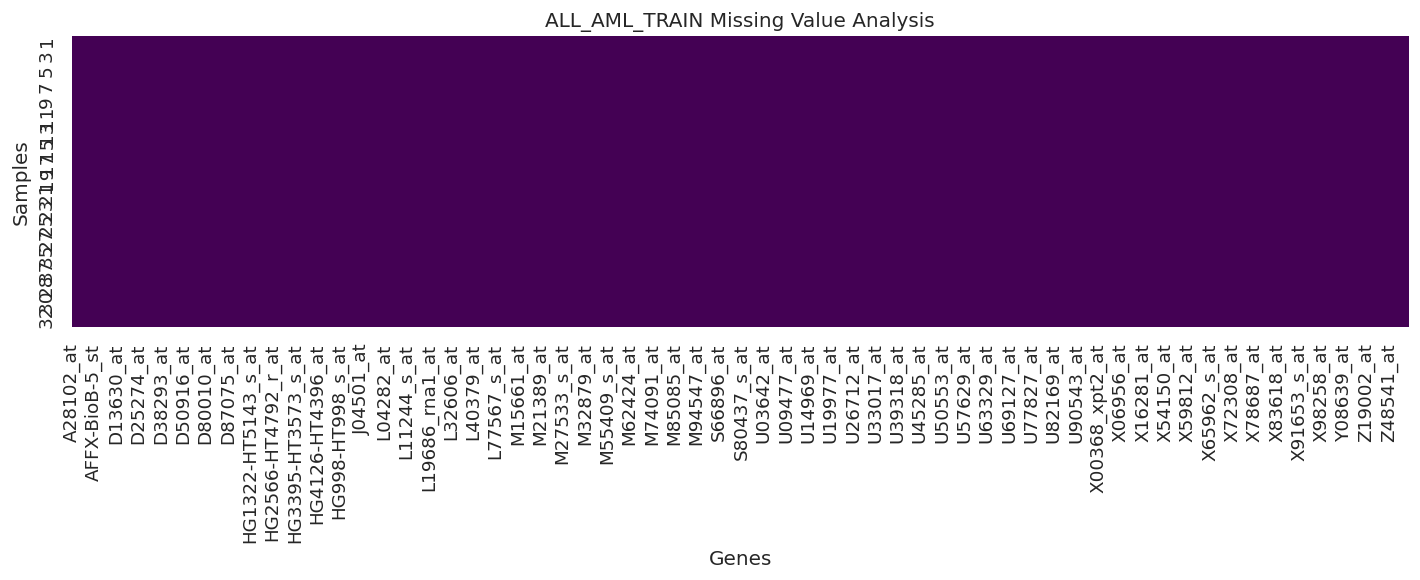

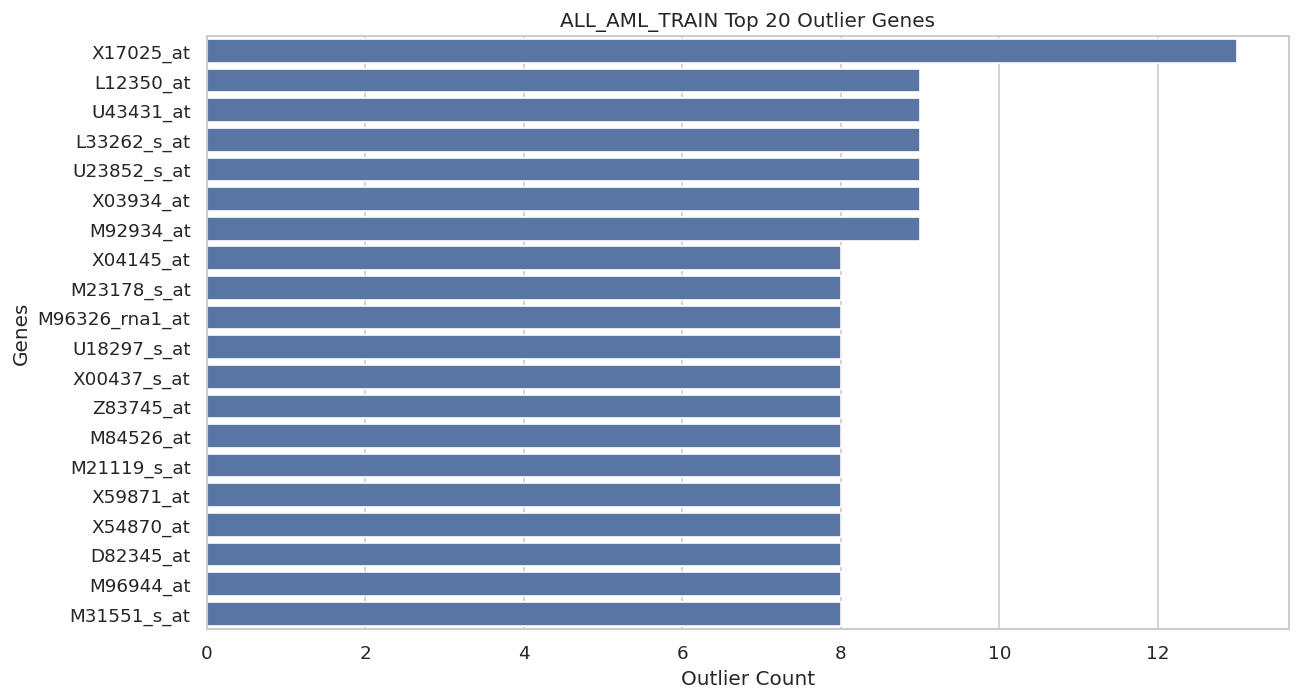

,Dataset,Samples,Genes,Missing,Positive_INF,Negative_INF,Total_INF,Negative,Zero,Duplicate_Genes,Total_Outliers,Genes_With_Outliers
0,ALL_AML_INDEPENDENT,34,7129,0,0,0,0,69999,877,0,10938,5160


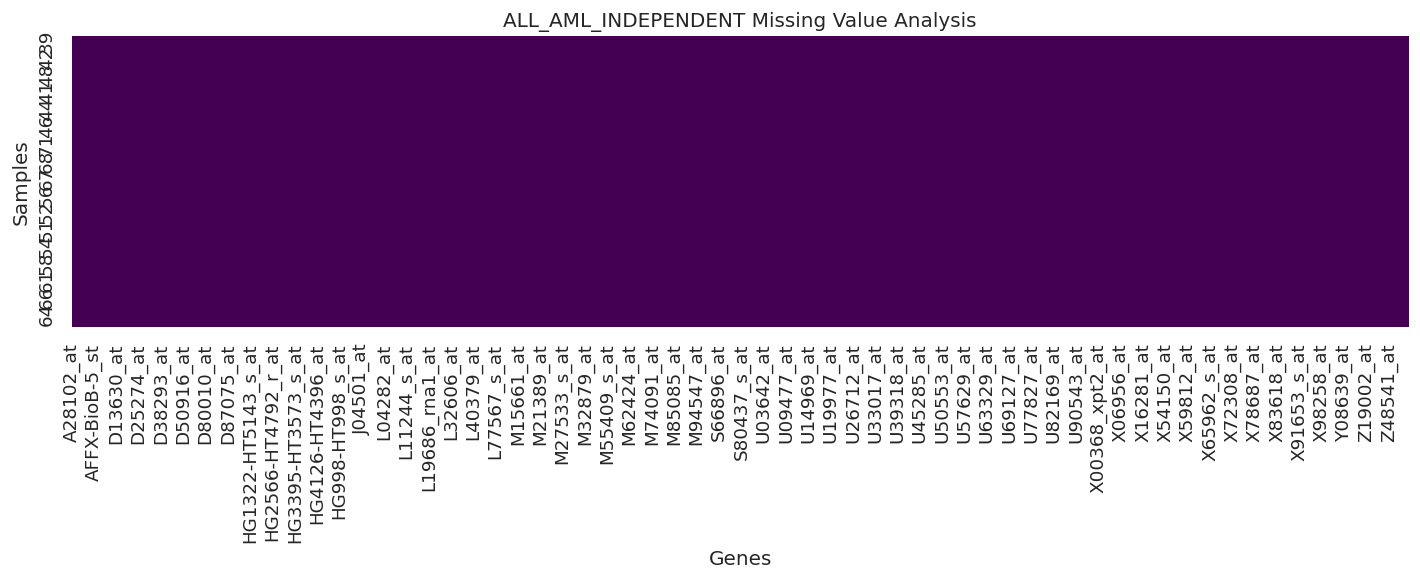

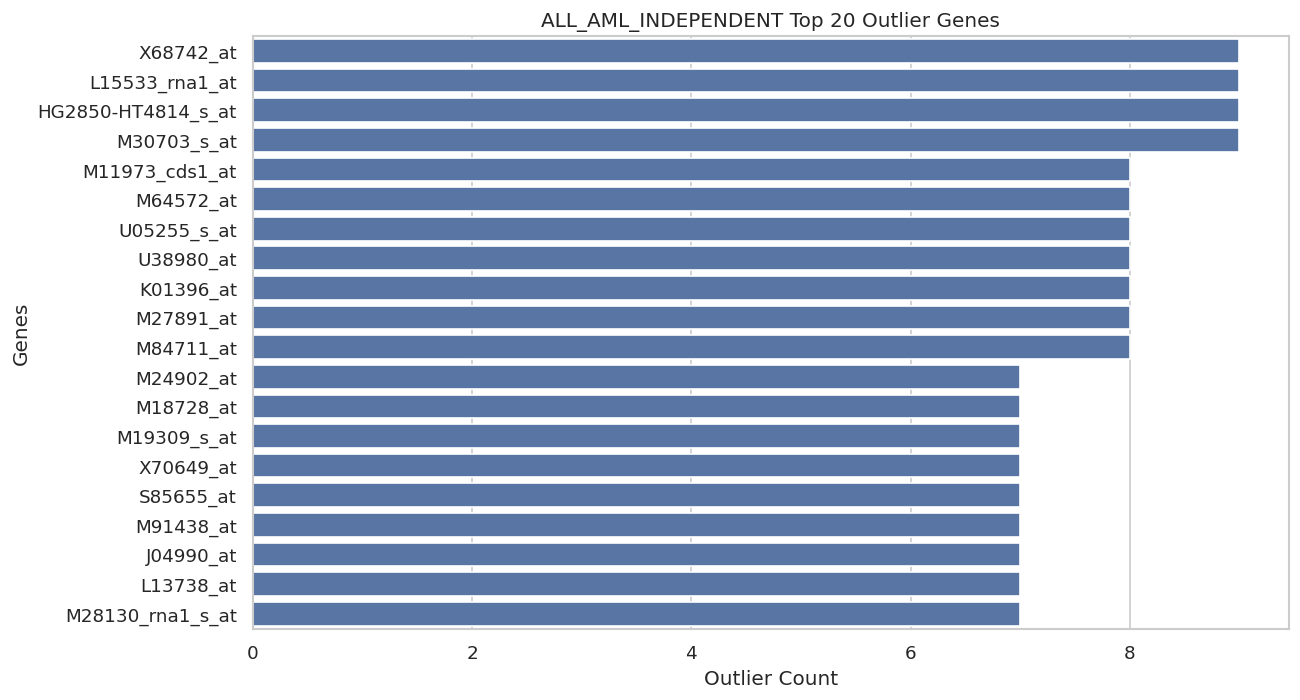

,Dataset,Samples,Genes,Missing,Positive_INF,Negative_INF,Total_INF,Negative,Zero,Duplicate_Genes,Total_Outliers,Genes_With_Outliers
0,ARMSTRONG,72,2194,0,0,0,0,79162,0,0,2243,250


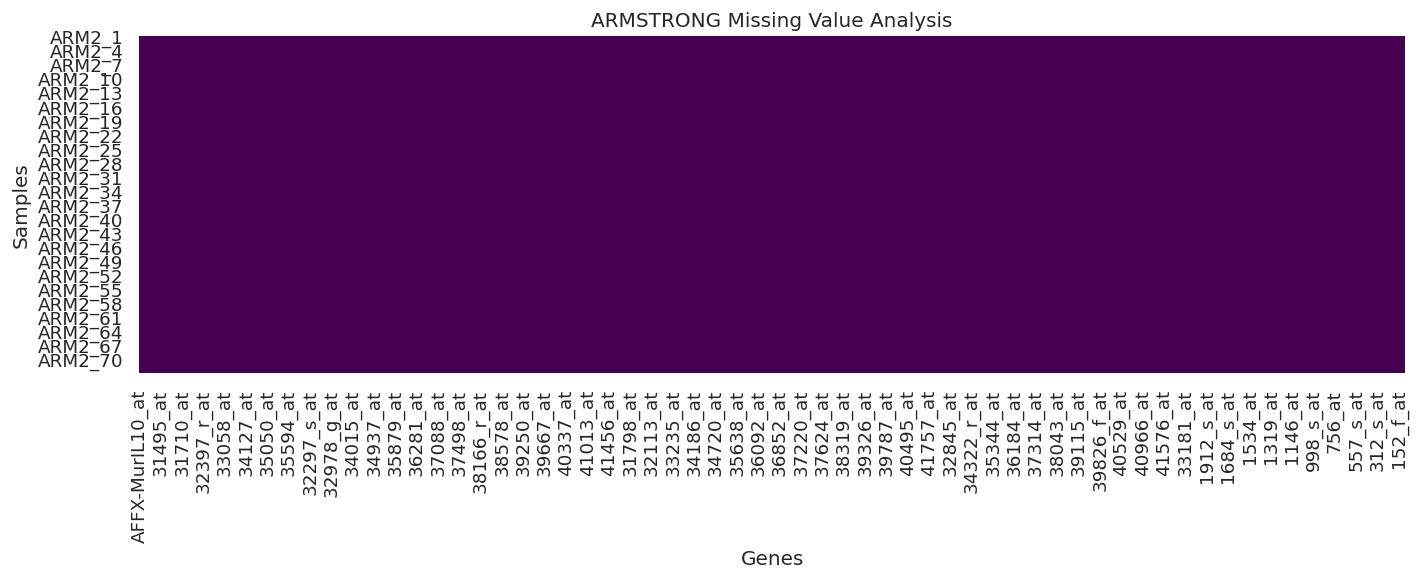

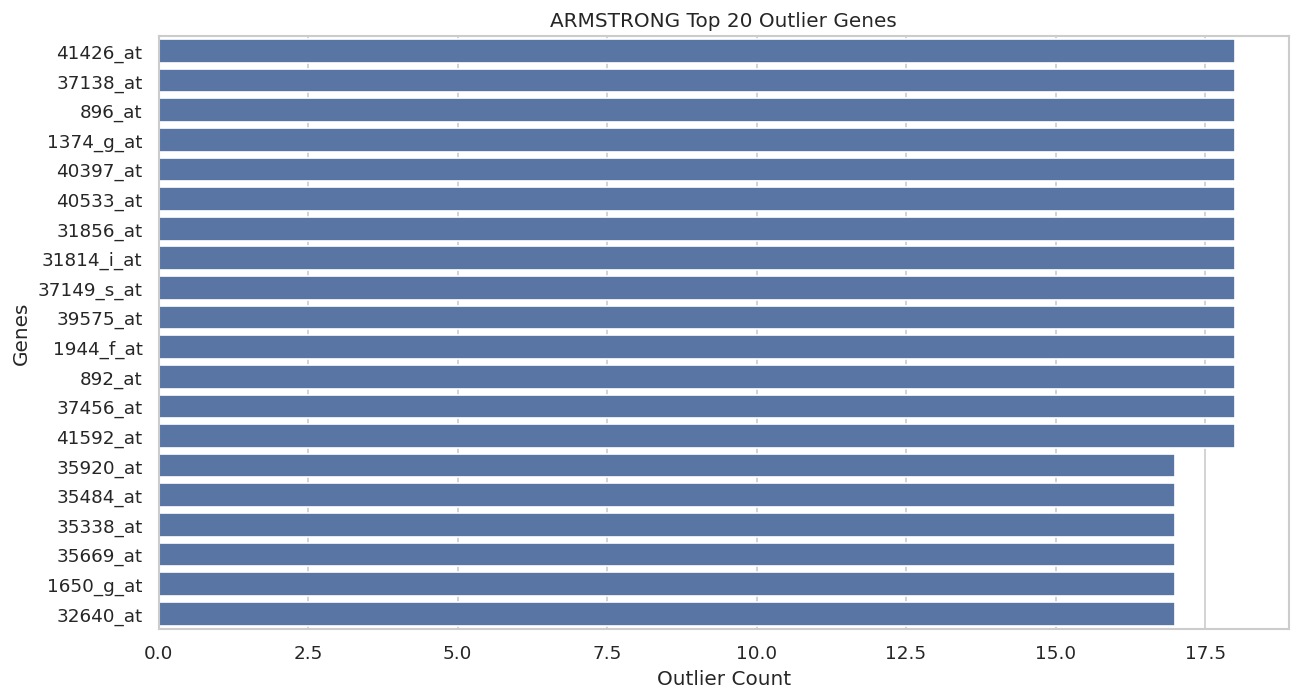


ALL_AML_TRAIN - negatif değer ön işlemi
1 ile değiştirilen negatif değer sayısı: 77175
İşlem sonrası negatif değer sayısı: 0
İşlem sonrası sıfır değer sayısı: 738

ALL_AML_INDEPENDENT - negatif değer ön işlemi
1 ile değiştirilen negatif değer sayısı: 69999
İşlem sonrası negatif değer sayısı: 0
İşlem sonrası sıfır değer sayısı: 877

ARMSTRONG - negatif değer ön işlemi
1 ile değiştirilen negatif değer sayısı: 79162
İşlem sonrası negatif değer sayısı: 0
İşlem sonrası sıfır değer sayısı: 0


In [4]:
def data_quality_analysis(X, dataset_name):

    X = X.apply(pd.to_numeric, errors="coerce")

    positive_inf = np.isposinf(X).sum().sum()
    negative_inf = np.isneginf(X).sum().sum()

    X = X.replace(
        [np.inf, -np.inf],
        np.nan
    )

    # IQR hesaplaması
    Q1 = X.quantile(0.25)
    Q3 = X.quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outlier_mask = (
        X.lt(lower, axis=1) |
        X.gt(upper, axis=1)
    )

    outlier_counts = outlier_mask.sum()

    report = {
        "Dataset": dataset_name,
        "Samples": X.shape[0],
        "Genes": X.shape[1],
        "Missing": X.isna().sum().sum(),
        "Positive_INF": positive_inf,
        "Negative_INF": negative_inf,
        "Total_INF": positive_inf + negative_inf,
        "Negative": (X < 0).sum().sum(),
        "Zero": (X == 0).sum().sum(),
        "Duplicate_Genes": X.columns.duplicated().sum(),
        "Total_Outliers": outlier_mask.sum().sum(),
        "Genes_With_Outliers": (outlier_counts > 0).sum()
    }

    report_df = pd.DataFrame([report])

    display(report_df)

    report_df.to_csv(
        f"{OUTPUT_DIR}/{dataset_name}_quality.csv",
        index=False
    )

    outlier_counts.to_csv(
        f"{OUTPUT_DIR}/{dataset_name}_outlier_counts.csv"
    )

    # Eksik değer grafiği
    plt.figure(figsize=(12, 5))

    sns.heatmap(
        X.isna(),
        cmap="viridis",
        cbar=False
    )

    plt.title(f"{dataset_name} Missing Value Analysis")
    plt.xlabel("Genes")
    plt.ylabel("Samples")

    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/{dataset_name}_missing.png",
        dpi=300
    )

    plt.show()

    # En fazla aykırı değer içeren 20 gen
    top_outliers = outlier_counts.sort_values(
        ascending=False
    ).head(20)

    plt.figure(figsize=(11, 6))

    sns.barplot(
        x=top_outliers.values,
        y=top_outliers.index.astype(str)
    )

    plt.title(f"{dataset_name} Top 20 Outlier Genes")
    plt.xlabel("Outlier Count")
    plt.ylabel("Genes")

    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/{dataset_name}_outliers.png",
        dpi=300
    )

    plt.show()

    return X


X_all = data_quality_analysis(X_all, "ALL_AML_TRAIN")

X_independent = data_quality_analysis(
    X_independent,
    "ALL_AML_INDEPENDENT"
)

X_arm2 = data_quality_analysis(X_arm2, "ARMSTRONG")



# ============================================================
# NEGATİF İFADE DEĞERLERİNİ 1 İLE DEĞİŞTİRME
# Bu adım veri kalitesi raporları oluşturulduktan sonra uygulanır.
# Böylece özgün negatif değer sayıları raporlarda korunur.
# Bundan sonraki analizler güncellenmiş X matrislerini kullanır.
# ============================================================

def replace_negative_values_with_one(X, dataset_name):

    X = X.copy()

    negative_mask = X < 0
    negative_count = int(negative_mask.sum().sum())

    # Yalnızca negatif değerleri 1 ile değiştirir.
    # Sıfır değerler bu adımda değiştirilmez.
    X = X.mask(negative_mask, 1)

    print(f"\n{dataset_name} - negatif değer ön işlemi")
    print("1 ile değiştirilen negatif değer sayısı:", negative_count)
    print("İşlem sonrası negatif değer sayısı:", int((X < 0).sum().sum()))
    print("İşlem sonrası sıfır değer sayısı:", int((X == 0).sum().sum()))

    summary = pd.DataFrame([{
        "Dataset": dataset_name,
        "Negative_Values_Replaced_With_1": negative_count,
        "Negative_Values_After": int((X < 0).sum().sum()),
        "Zero_Values_After": int((X == 0).sum().sum())
    }])

    summary.to_csv(
        f"{OUTPUT_DIR}/{dataset_name}_negative_value_replacement.csv",
        index=False
    )

    return X



X_all = replace_negative_values_with_one(
    X_all,
    "ALL_AML_TRAIN"
)

X_independent = replace_negative_values_with_one(
    X_independent,
    "ALL_AML_INDEPENDENT"
)

X_arm2 = replace_negative_values_with_one(
    X_arm2,
    "ARMSTRONG"
)


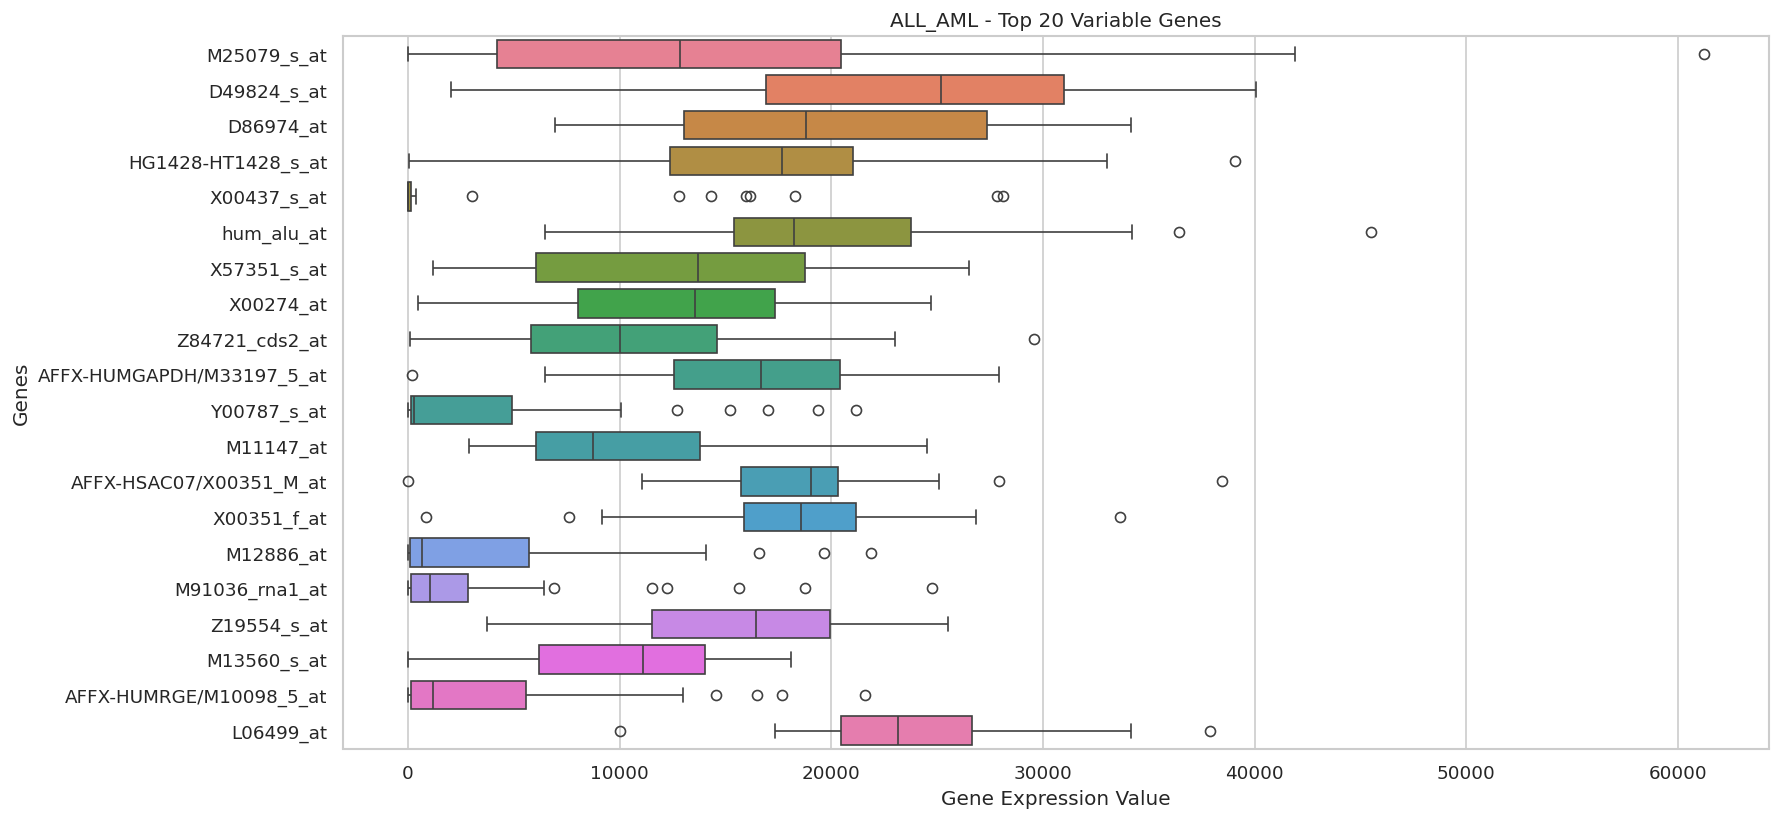

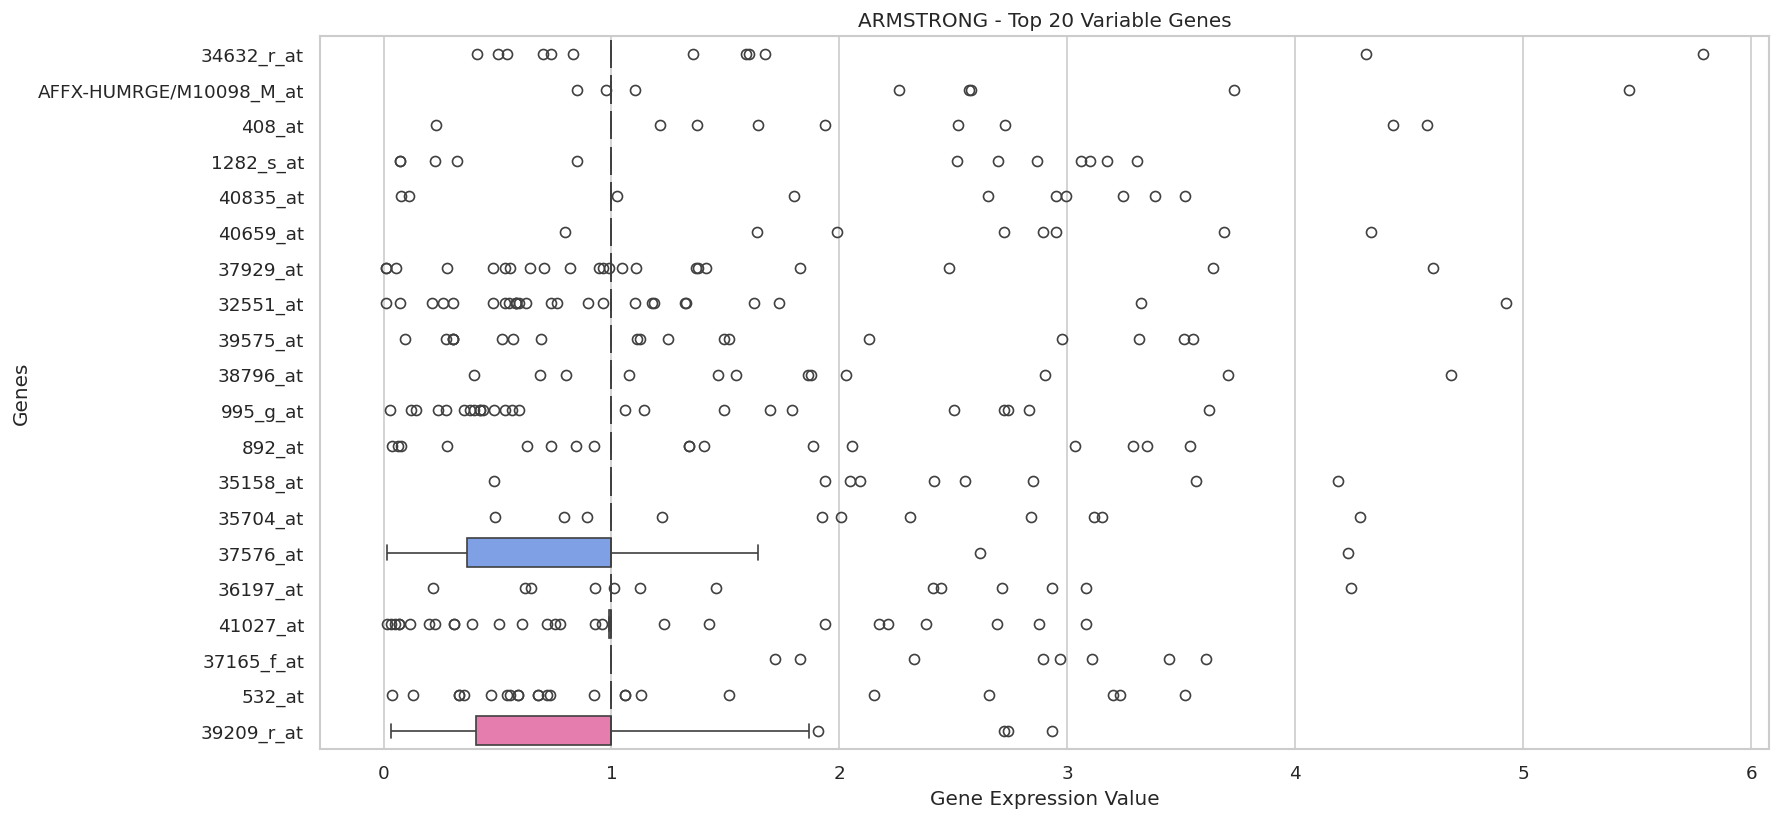

In [5]:
def outlier_boxplot(X, dataset_name):

    # En yüksek varyansa sahip 20 geni seç
    top_genes = X.var().sort_values(
        ascending=False
    ).head(20).index

    plt.figure(figsize=(15, 7))

    sns.boxplot(
        data=X[top_genes],
        orient="h",
        showfliers=True
    )

    plt.title(
        f"{dataset_name} - Top 20 Variable Genes"
    )

    plt.xlabel("Gene Expression Value")
    plt.ylabel("Genes")

    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/{dataset_name}_boxplot.png",
        dpi=300
    )

    plt.show()


outlier_boxplot(X_all, "ALL_AML")

outlier_boxplot(X_arm2, "ARMSTRONG")

,Sample,Outlier_Count,Outlier_Percentage
19,20,1368,19.189227
16,17,1106,15.514097
37,33,757,10.618600
20,21,654,9.173797
29,36,556,7.799130
34,30,555,7.785103
8,9,530,7.434423
30,37,478,6.705008
2,3,473,6.634872
7,8,456,6.396409


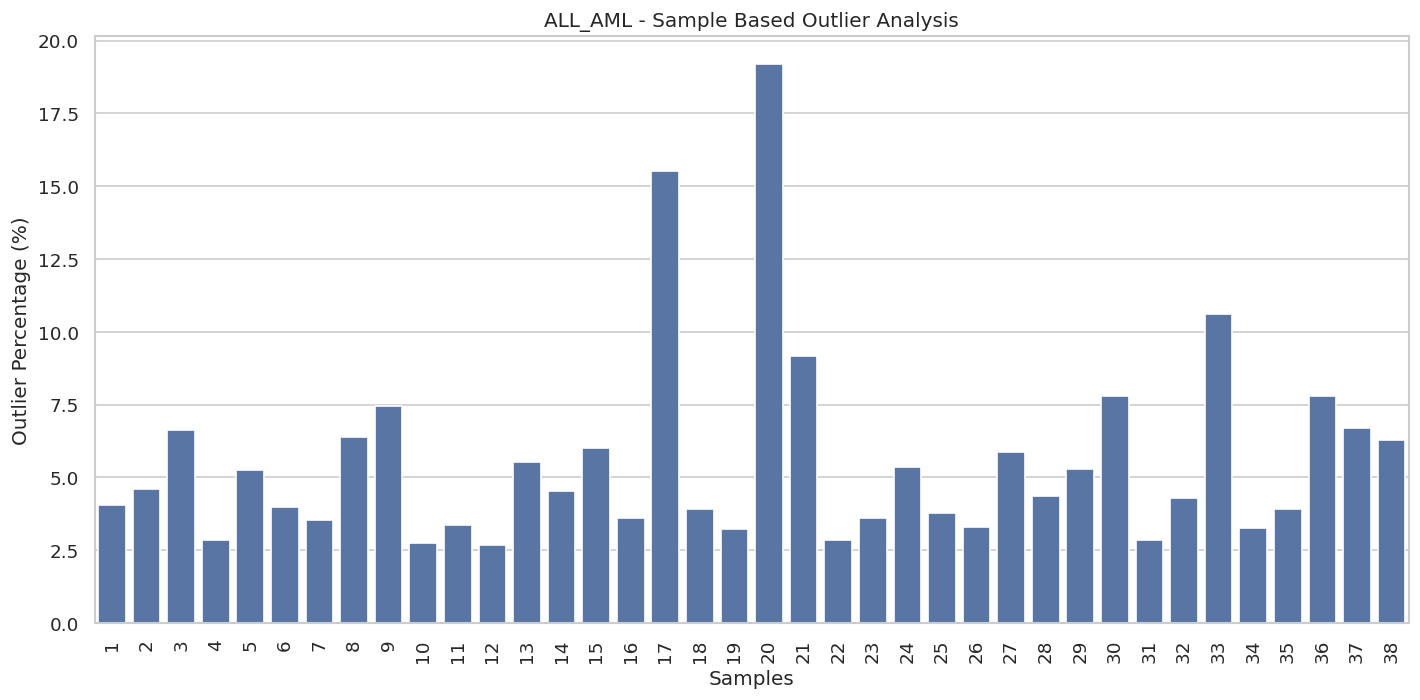

,Sample,Outlier_Count,Outlier_Percentage
40,ARM2_41,613,27.939836
1,ARM2_2,592,26.982680
6,ARM2_7,589,26.845943
62,ARM2_63,577,26.298997
0,ARM2_1,574,26.162261
7,ARM2_8,558,25.432999
10,ARM2_11,557,25.387420
21,ARM2_22,553,25.205105
13,ARM2_14,551,25.113947
24,ARM2_25,550,25.068368


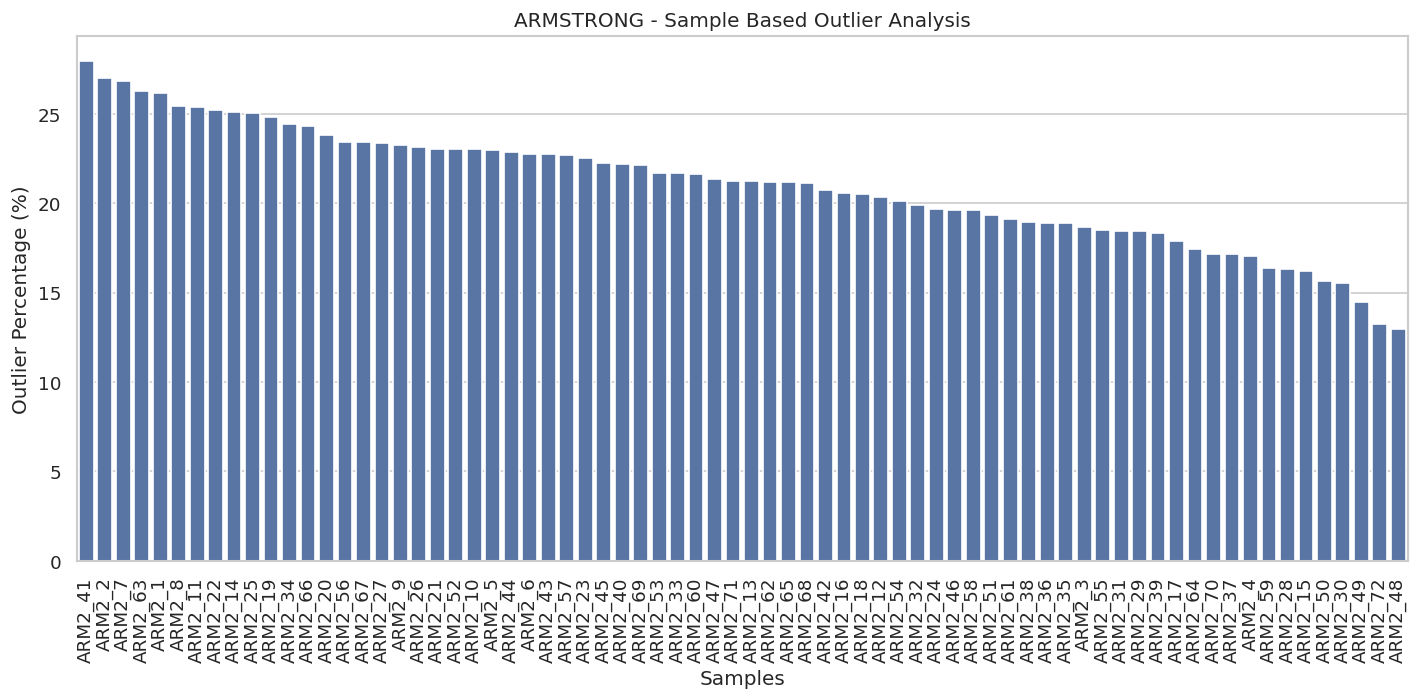

In [6]:
def sample_outlier_analysis(X, dataset_name):

    Q1 = X.quantile(0.25)

    Q3 = X.quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR

    upper = Q3 + 1.5 * IQR

    outlier_mask = (
        X.lt(lower, axis=1) |
        X.gt(upper, axis=1)
    )

    # Her örnekteki uç değer sayısı
    sample_outliers = outlier_mask.sum(axis=1)

    results = pd.DataFrame({
        "Sample": X.index,
        "Outlier_Count": sample_outliers.values,
        "Outlier_Percentage": (
            sample_outliers.values / X.shape[1]
        ) * 100
    })

    results = results.sort_values(
        "Outlier_Count",
        ascending=False
    )

    display(results.head(15))

    results.to_csv(
        f"{OUTPUT_DIR}/{dataset_name}_sample_outliers.csv",
        index=False
    )

    plt.figure(figsize=(12, 6))

    sns.barplot(
        data=results,
        x="Sample",
        y="Outlier_Percentage"
    )

    plt.xticks(rotation=90)

    plt.title(
        f"{dataset_name} - Sample Based Outlier Analysis"
    )

    plt.xlabel("Samples")

    plt.ylabel("Outlier Percentage (%)")

    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/{dataset_name}_sample_outliers.png",
        dpi=300
    )

    plt.show()

    return results


all_sample_outliers = sample_outlier_analysis(
    X_all,
    "ALL_AML"
)

arm_sample_outliers = sample_outlier_analysis(
    X_arm2,
    "ARMSTRONG"
)

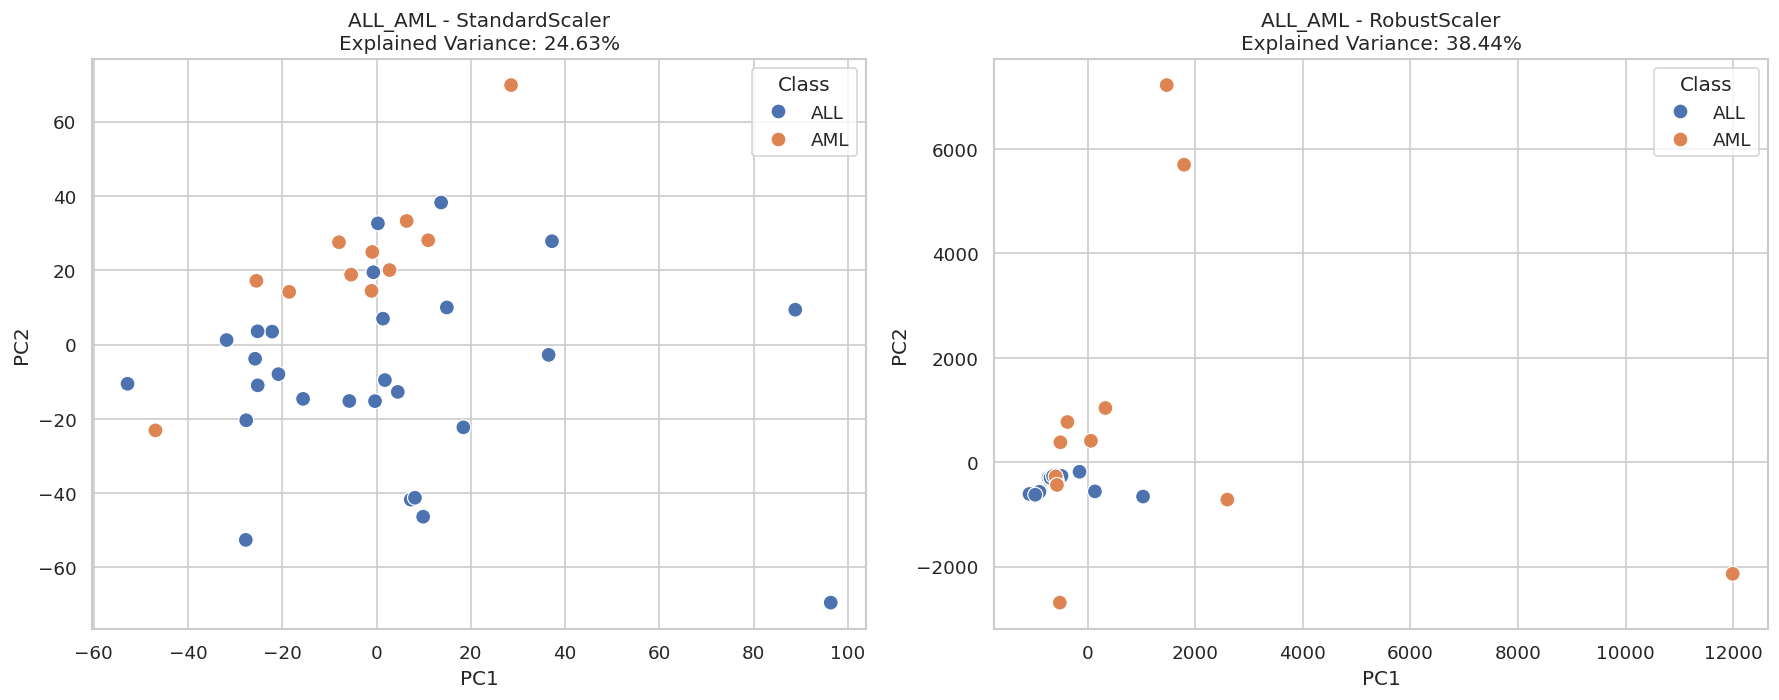

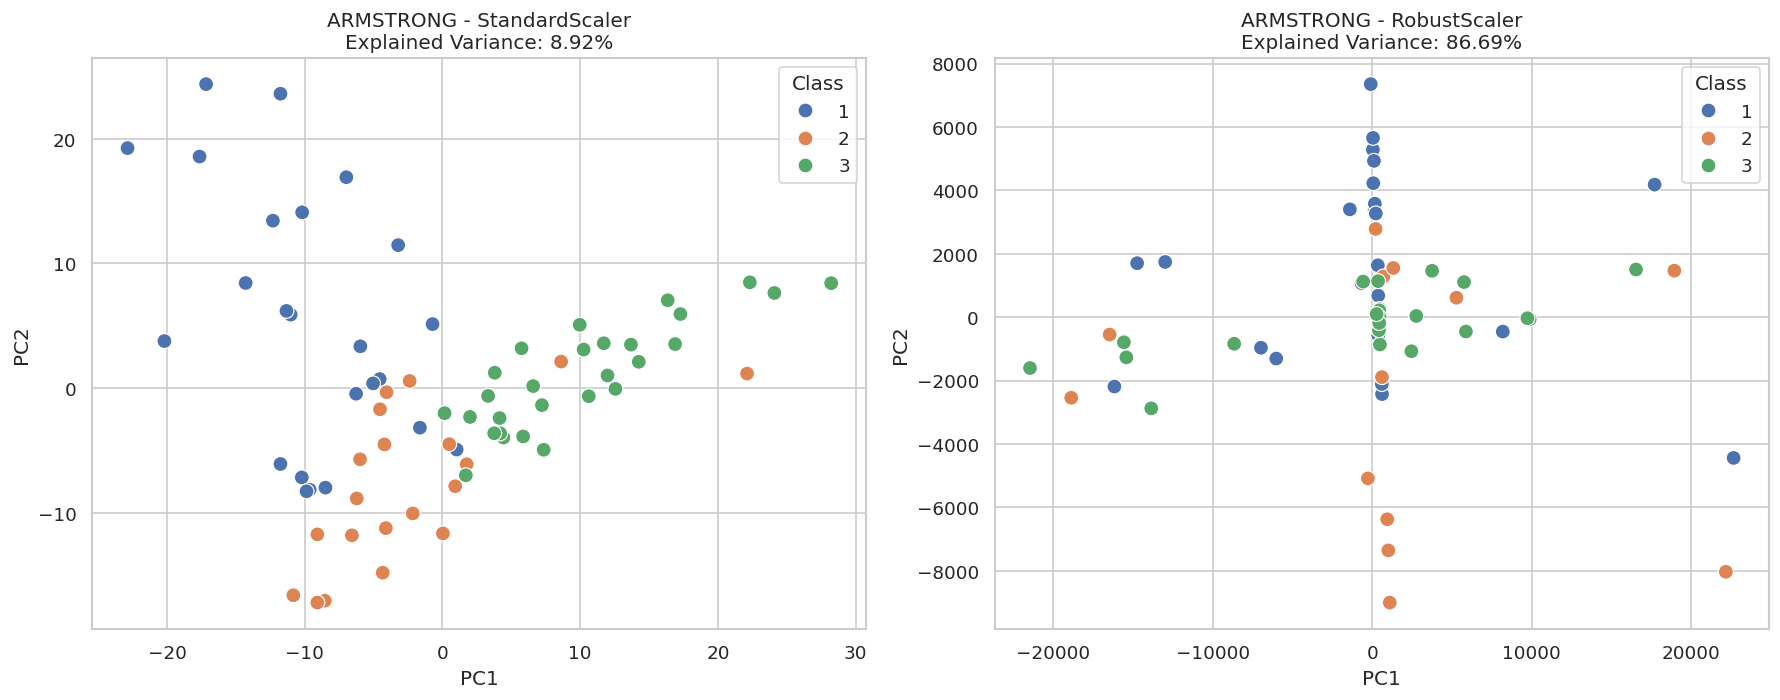

In [7]:
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer


def compare_scalers(X, y, dataset_name):

    X = X.replace(
        [np.inf, -np.inf],
        np.nan
    )

    X = X.dropna(axis=1, how="all")

    imputer = SimpleImputer(
        strategy="median"
    )

    X_imputed = imputer.fit_transform(X)

    scalers = {
        "StandardScaler": StandardScaler(),
        "RobustScaler": RobustScaler()
    }

    fig, axes = plt.subplots(
        1, 2,
        figsize=(15, 6)
    )

    for ax, (name, scaler) in zip(
        axes,
        scalers.items()
    ):

        X_scaled = scaler.fit_transform(
            X_imputed
        )

        pca = PCA(
            n_components=2
        )

        components = pca.fit_transform(
            X_scaled
        )

        result = pd.DataFrame({
            "PC1": components[:, 0],
            "PC2": components[:, 1],
            "Class": np.asarray(y).astype(str)
        })

        sns.scatterplot(
            data=result,
            x="PC1",
            y="PC2",
            hue="Class",
            ax=ax,
            s=80
        )

        ax.set_title(
            f"{dataset_name} - {name}\n"
            f"Explained Variance: "
            f"{pca.explained_variance_ratio_.sum()*100:.2f}%"
        )

    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/{dataset_name}_scaler_comparison.png",
        dpi=300
    )

    plt.show()


compare_scalers(
    X_all,
    y_all,
    "ALL_AML"
)

compare_scalers(
    X_arm2,
    y_arm2,
    "ARMSTRONG"
)

ALL_AML_TRAIN P/A/M dağılımı:


,Count
P,78632
A,187892
M,4378


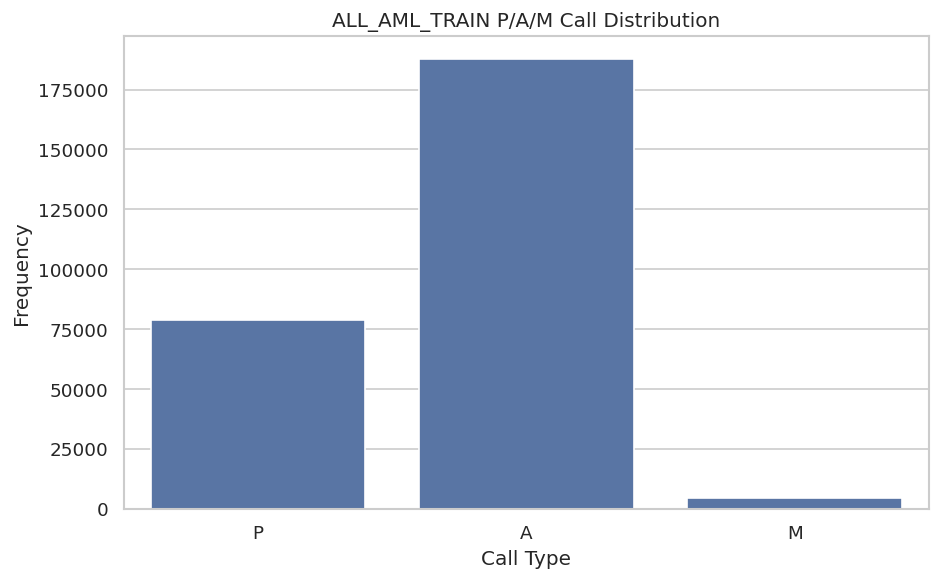

ALL_AML_INDEPENDENT P/A/M dağılımı:


,Count
P,66244
A,172247
M,3895


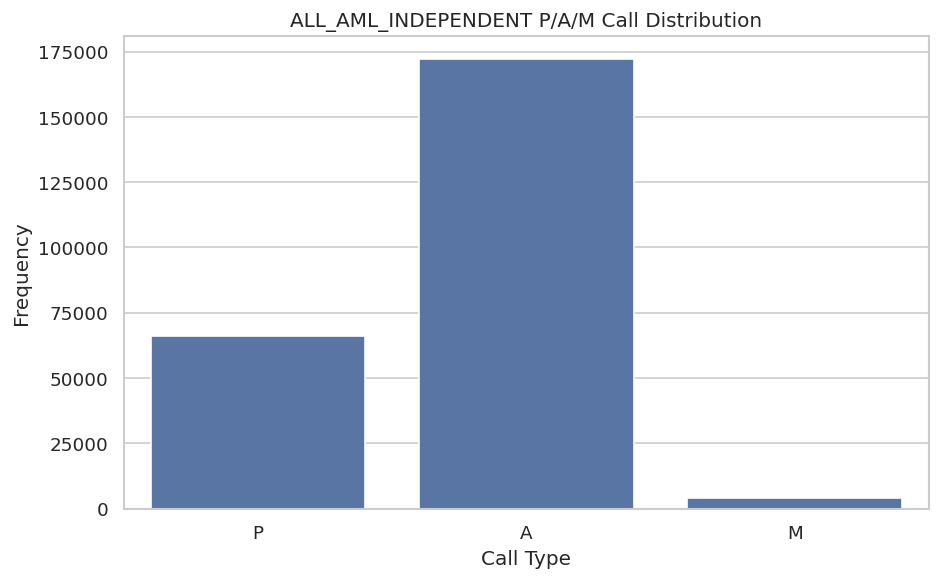

In [8]:
def analyze_calls(df, dataset_name):

    call_columns = [
        c for c in df.columns
        if str(c).lower() == "call"
        or str(c).lower().startswith("call.")
    ]

    if not call_columns:
        print("P/A/M sütunları bulunamadı.")
        return None

    calls = df[call_columns].copy()

    calls = calls.astype(str).apply(
        lambda col: col.str.strip().str.upper()
    )

    counts = calls.stack().value_counts()

    counts = counts.reindex(
        ["P", "A", "M"],
        fill_value=0
    )

    print(dataset_name, "P/A/M dağılımı:")
    display(counts.to_frame("Count"))

    counts.to_csv(
        f"{OUTPUT_DIR}/{dataset_name}_PAM.csv"
    )

    plt.figure(figsize=(8, 5))

    sns.barplot(
        x=counts.index,
        y=counts.values
    )

    plt.title(f"{dataset_name} P/A/M Call Distribution")
    plt.xlabel("Call Type")
    plt.ylabel("Frequency")

    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/{dataset_name}_PAM.png",
        dpi=300
    )

    plt.show()

    return counts


pam_train = analyze_calls(
    all_raw,
    "ALL_AML_TRAIN"
)

pam_test = analyze_calls(
    independent_raw,
    "ALL_AML_INDEPENDENT"
)

In [9]:
def descriptive_analysis(X, dataset_name):

    stats = X.describe(
        percentiles=[
            0.01,
            0.25,
            0.50,
            0.75,
            0.99
        ]
    )

    stats.to_csv(
        f"{OUTPUT_DIR}/{dataset_name}_statistics.csv"
    )

    display(stats)

    return stats


stats_all = descriptive_analysis(
    X_all,
    "ALL_AML_TRAIN"
)

stats_test = descriptive_analysis(
    X_independent,
    "ALL_AML_INDEPENDENT"
)

stats_arm2 = descriptive_analysis(
    X_arm2,
    "ARMSTRONG"
)

Gene Accession Number,A28102_at,AB000114_at,AB000115_at,AB000220_at,AB000381_s_at,AB000409_at,AB000410_s_at,AB000449_at,AB000450_at,AB000460_at,...,Z84721_cds2_at,Z84722_at,Z86000_at,Z93784_at,Z94753_s_at,Z95624_at,Z96810_at,Z97054_xpt2_at,Z97074_at,hum_alu_at
count,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,...,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000
mean,275.210526,39.105263,313.947368,39.289474,57.026316,75.815789,4.000000,244.052632,168.131579,1892.710526,...,10505.763158,4.210526,648.000000,388.815789,111.947368,108.526316,7.815789,527.236842,172.052632,20276.657895
std,184.372590,41.794083,428.433725,38.179454,44.532094,111.277801,12.973986,196.909905,115.136857,483.499680,...,6456.583225,19.791013,249.907983,235.740335,61.386656,51.829104,16.264462,196.434218,128.183767,7546.053808
min,20.000000,0.000000,71.000000,1.000000,1.000000,1.000000,1.000000,28.000000,19.000000,976.000000,...,74.000000,1.000000,287.000000,42.000000,1.000000,20.000000,0.000000,159.000000,1.000000,6479.000000
1%,29.620000,0.370000,72.110000,1.000000,1.000000,1.000000,1.000000,30.960000,20.480000,1091.440000,...,99.530000,1.000000,304.760000,58.650000,5.070000,24.810000,0.000000,188.230000,1.000000,8165.830000
25%,125.250000,1.000000,152.000000,14.500000,12.750000,1.000000,1.000000,121.250000,96.750000,1487.750000,...,5807.000000,1.000000,456.750000,198.500000,63.250000,65.250000,1.000000,401.500000,115.000000,15394.750000
50%,255.000000,32.000000,197.000000,37.500000,51.000000,20.500000,1.000000,189.000000,169.500000,1804.500000,...,10017.500000,1.000000,585.500000,380.000000,112.500000,100.500000,1.000000,512.500000,146.000000,18255.000000
75%,386.500000,59.750000,273.250000,42.750000,86.750000,115.750000,1.000000,310.000000,216.000000,2125.250000,...,14576.250000,1.000000,798.500000,482.750000,144.000000,145.750000,1.000000,655.750000,214.750000,23775.750000
99%,785.790000,166.600000,1959.050000,180.900000,145.150000,414.170000,59.560000,912.540000,530.840000,3075.430000,...,27155.990000,77.860000,1323.470000,988.730000,250.580000,222.190000,63.860000,990.740000,524.450000,42134.250000
max,872.000000,174.000000,2194.000000,192.000000,147.000000,436.000000,64.000000,971.000000,556.000000,3172.000000,...,29588.000000,123.000000,1386.000000,1015.000000,275.000000,227.000000,72.000000,1027.000000,567.000000,45492.000000


Gene Accession Number,A28102_at,AB000114_at,AB000115_at,AB000220_at,AB000381_s_at,AB000409_at,AB000410_s_at,AB000449_at,AB000450_at,AB000460_at,...,Z84721_cds2_at,Z84722_at,Z86000_at,Z93784_at,Z94753_s_at,Z95624_at,Z96810_at,Z97054_xpt2_at,Z97074_at,hum_alu_at
count,34.000000,34.000000,34.000000,34.000000,34.000000,34.000000,34.0,34.000000,34.000000,34.000000,...,34.000000,34.000000,34.000000,34.000000,34.000000,34.000000,34.000000,34.000000,34.000000,34.000000
mean,281.147059,46.058824,276.470588,55.764706,40.529412,94.029412,1.0,182.088235,191.617647,1747.382353,...,14222.441176,1.794118,617.264706,230.058824,89.470588,99.205882,14.558824,511.323529,141.058824,30722.000000
std,197.436316,58.497833,304.966986,49.042380,41.072910,175.134318,0.0,158.864029,113.615517,638.959240,...,10605.534059,4.630462,292.906988,175.187162,64.339646,37.112262,28.826746,283.704896,155.641768,11473.175442
min,59.000000,0.000000,65.000000,1.000000,1.000000,0.000000,1.0,1.000000,2.000000,714.000000,...,1.000000,1.000000,29.000000,2.000000,1.000000,26.000000,1.000000,96.000000,1.000000,11195.000000
1%,60.980000,0.330000,65.330000,1.000000,1.000000,0.330000,1.0,6.610000,22.130000,737.430000,...,36.970000,1.000000,97.640000,22.790000,1.000000,31.280000,1.000000,106.230000,1.000000,12678.020000
25%,139.750000,1.000000,124.750000,26.750000,4.000000,1.000000,1.0,72.750000,114.000000,1308.250000,...,5580.000000,1.000000,446.250000,133.750000,44.250000,64.750000,1.000000,336.250000,1.000000,21025.750000
50%,254.500000,30.000000,160.500000,45.500000,31.500000,5.500000,1.0,145.000000,168.500000,1610.500000,...,12283.000000,1.000000,623.000000,202.500000,78.000000,108.000000,1.000000,439.500000,102.500000,29090.000000
75%,379.000000,65.500000,251.750000,68.000000,57.750000,124.000000,1.0,258.500000,248.500000,1989.250000,...,21247.250000,1.000000,717.500000,262.250000,123.000000,127.250000,8.750000,589.000000,212.500000,39484.250000
99%,924.170000,227.880000,1330.580000,190.450000,136.030000,703.760000,1.0,684.170000,480.370000,3338.010000,...,40066.680000,19.090000,1466.650000,835.850000,263.020000,159.350000,108.390000,1230.470000,604.630000,55304.280000
max,1106.000000,249.000000,1421.000000,202.000000,139.000000,845.000000,1.0,833.000000,517.000000,3570.000000,...,43434.000000,28.000000,1531.000000,920.000000,298.000000,161.000000,114.000000,1244.000000,700.000000,58203.000000


,AFFX-MurIL10_at,AFFX-PheX-3_at,AFFX-HUMISGF3A/M97935_5_at,AFFX-HUMISGF3A/M97935_MA_at,AFFX-HUMRGE/M10098_5_at,AFFX-HUMRGE/M10098_M_at,AFFX-HUMTFRR/M11507_M_at,AFFX-M27830_5_at,31312_at,31314_at,...,112_g_at,115_at,118_at,120_at,122_at,123_at,135_g_at,101_at,103_at,107_at
count,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000,...,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000
mean,0.916127,1.003410,0.959621,0.795356,1.041700,1.160163,0.940502,0.803465,0.986065,0.950579,...,0.909228,0.964788,1.086792,0.887765,1.015155,0.900247,0.999873,1.057311,0.868152,0.834158
std,0.324748,0.252809,0.422950,0.415648,0.411662,0.672695,0.424156,0.527349,0.247825,0.321343,...,0.361921,0.482666,0.407703,0.415225,0.264540,0.358283,0.358785,0.313252,0.399089,0.315375
min,0.014983,0.294518,0.062603,0.029837,0.404311,0.848665,0.026142,0.037357,0.018517,0.126010,...,0.086885,0.087472,0.080859,0.011415,0.314980,0.063297,0.122162,0.063714,0.017717,0.052391
1%,0.014983,0.338573,0.069580,0.039069,0.440256,0.937762,0.076264,0.043057,0.236417,0.175432,...,0.099070,0.099401,0.161369,0.011415,0.440024,0.092908,0.185615,0.148335,0.025039,0.080201
25%,0.760753,1.000000,0.872095,0.444495,0.997710,1.000000,0.789415,0.320755,0.994843,0.984786,...,0.826313,0.825214,1.000000,0.614971,1.000000,0.787907,0.976141,1.000000,0.590898,0.707200
50%,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
75%,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.001112,...,1.000000,1.000000,1.015737,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
99%,1.609347,1.680677,2.079338,1.747005,2.493959,4.235469,1.932857,2.314145,1.550401,1.679934,...,1.734439,2.661459,2.418545,1.921068,1.688683,1.634192,2.100925,1.986368,1.888534,1.387822
max,1.841470,1.839553,2.456276,1.889473,3.315058,5.464297,1.947681,2.391259,1.612543,1.792929,...,1.737561,2.723571,2.602641,2.095700,1.715787,1.850785,2.541843,2.015822,2.090850,1.554947


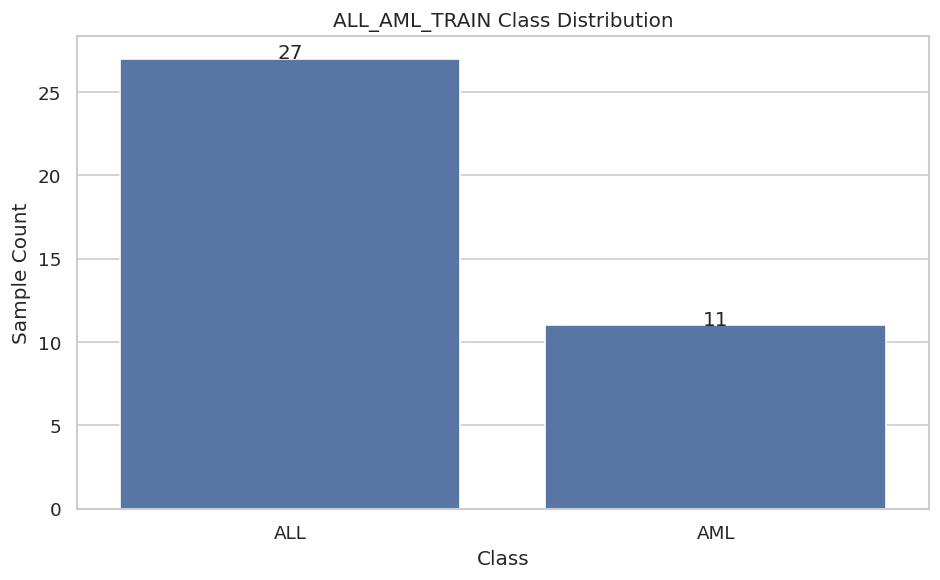

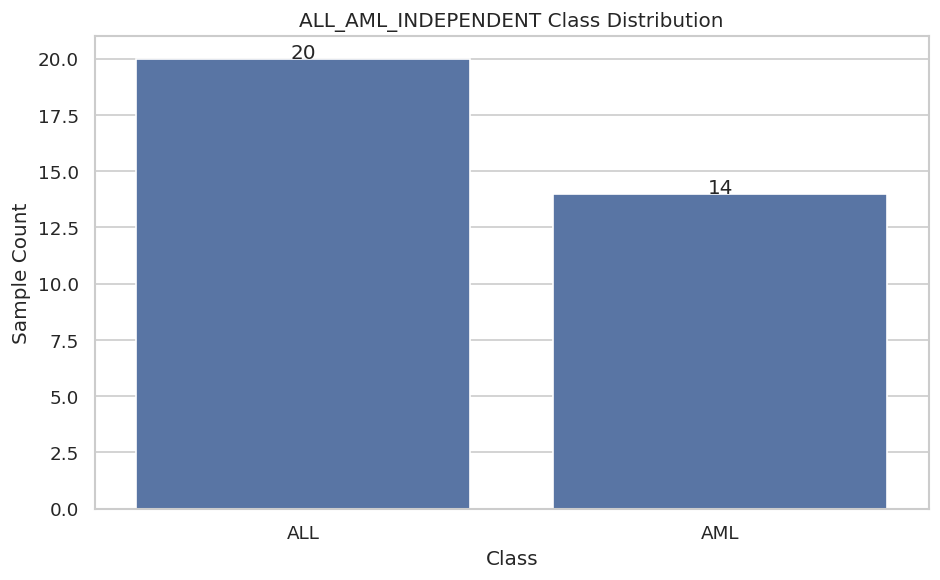

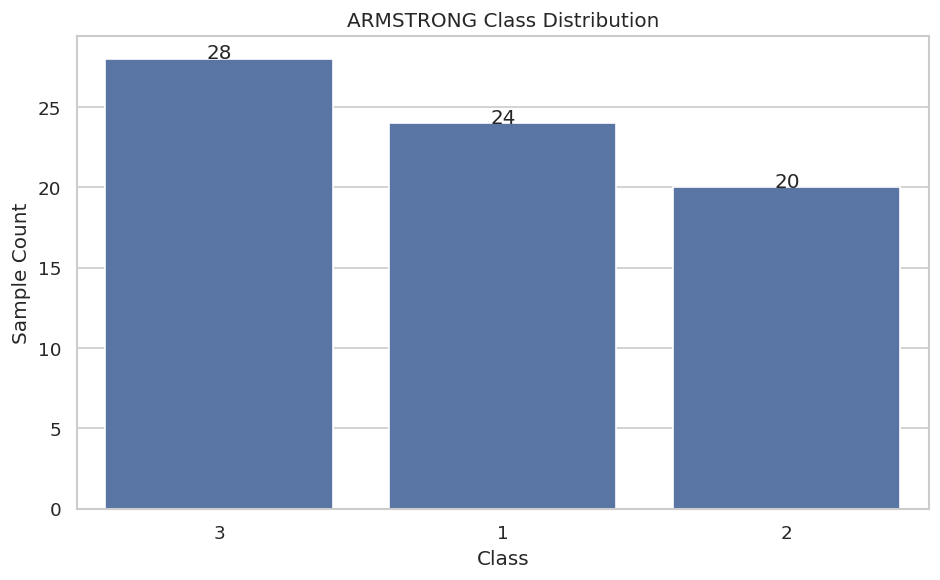

group
3    28
1    24
2    20
Name: count, dtype: int64

In [10]:
def class_distribution(y, dataset_name):

    counts = y.value_counts()

    plt.figure(figsize=(8, 5))

    sns.barplot(
        x=counts.index.astype(str),
        y=counts.values
    )

    plt.title(f"{dataset_name} Class Distribution")
    plt.xlabel("Class")
    plt.ylabel("Sample Count")

    for i, value in enumerate(counts.values):
        plt.text(i, value, str(value), ha="center")

    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/{dataset_name}_class_distribution.png",
        dpi=300
    )

    plt.show()

    return counts


class_distribution(y_all, "ALL_AML_TRAIN")
class_distribution(y_independent, "ALL_AML_INDEPENDENT")
class_distribution(y_arm2, "ARMSTRONG")

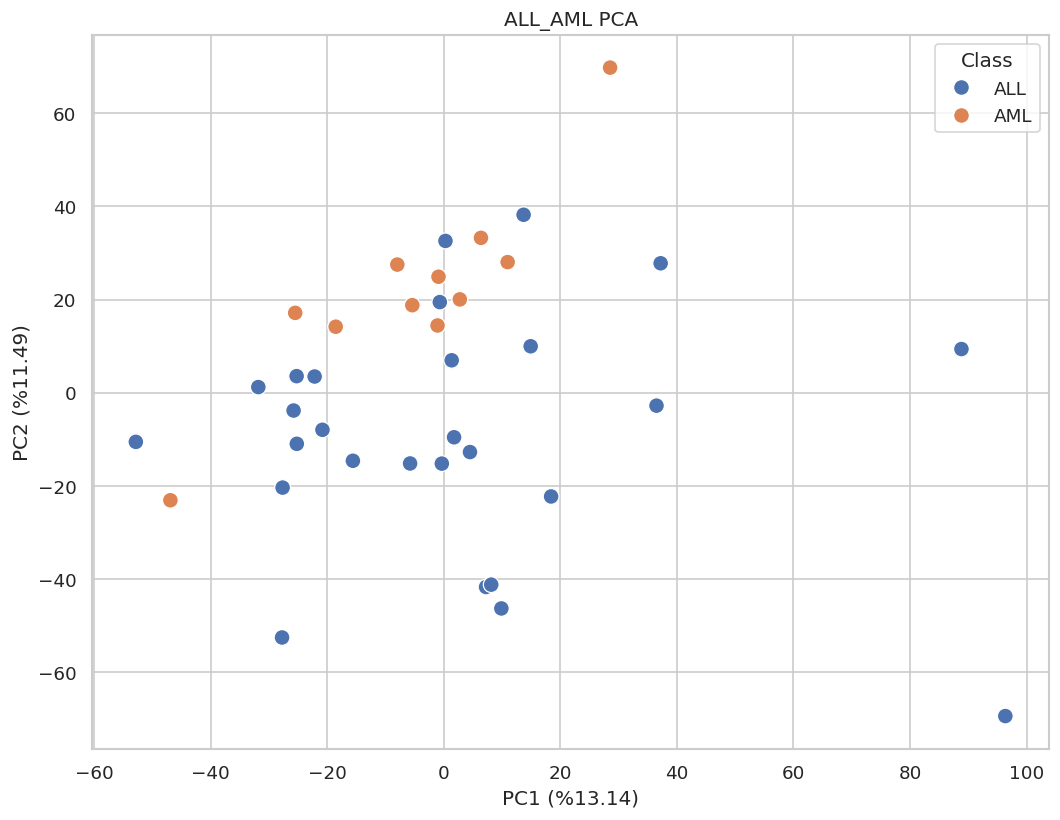

PC1: 0.13137404550950318
PC2: 0.11491012897903109
İlk iki bileşenin toplam varyansı: 0.2462841744885343


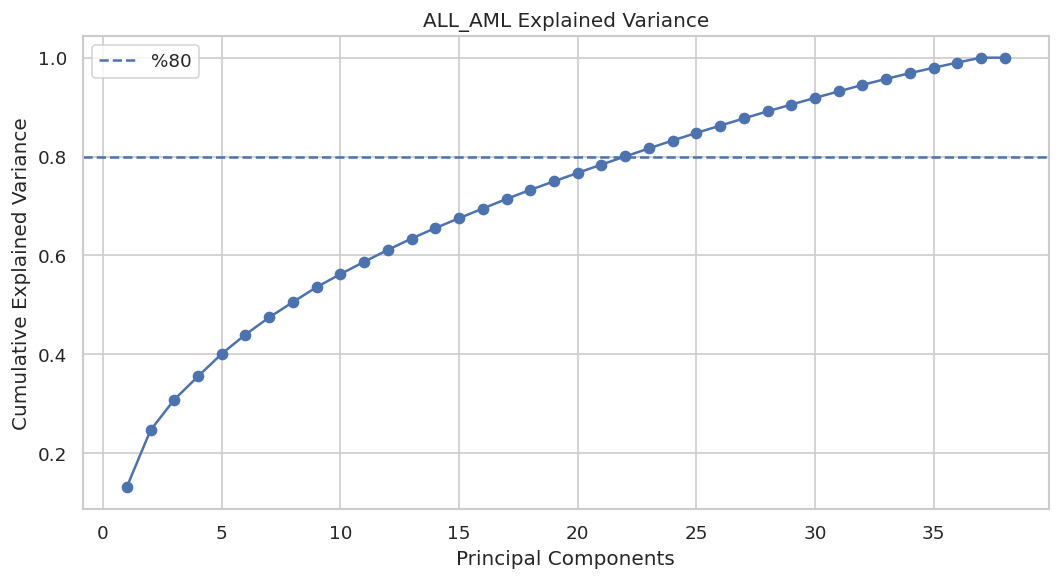

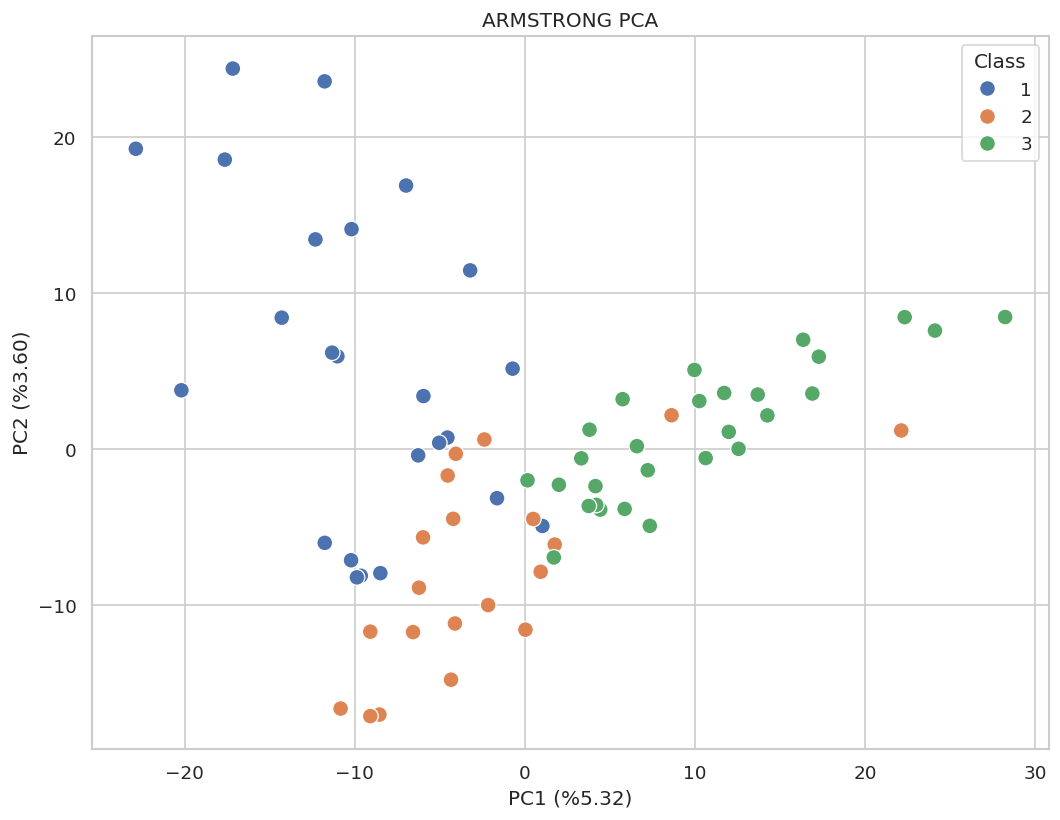

PC1: 0.053208811983052176
PC2: 0.03595518418714555
İlk iki bileşenin toplam varyansı: 0.08916399617019773


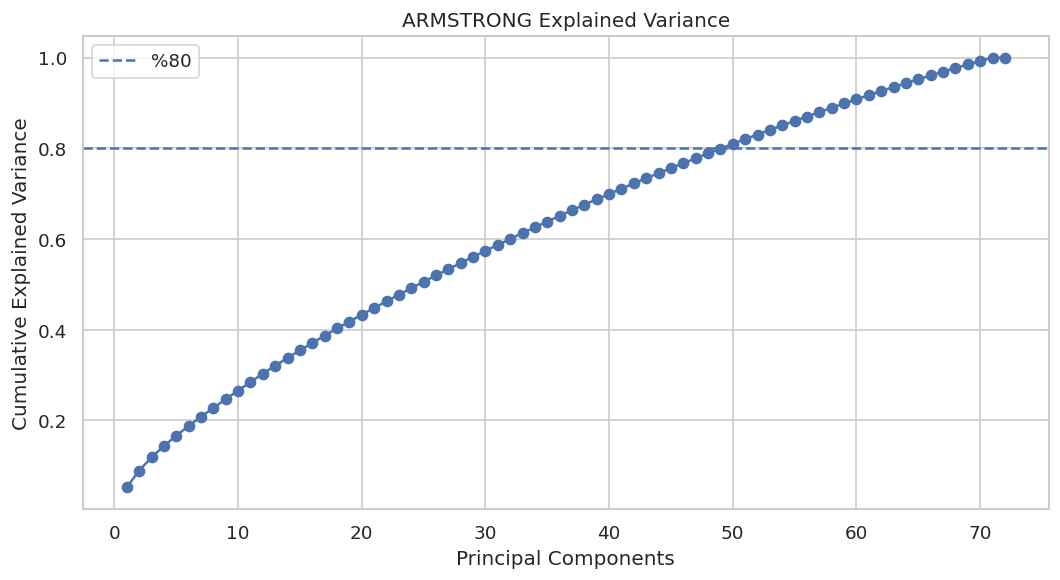

In [11]:
def prepare_for_analysis(X, fit_imputer=None):

    X = X.copy()

    X = X.replace(
        [np.inf, -np.inf],
        np.nan
    )

    # Tamamen boş genleri çıkar
    X = X.dropna(axis=1, how="all")

    if fit_imputer is None:

        imputer = SimpleImputer(
            strategy="median"
        )

        transformed = imputer.fit_transform(X)

    else:

        imputer = fit_imputer

        transformed = imputer.transform(X)

    return transformed, imputer


def run_pca(X, y, dataset_name):

    values, imputer = prepare_for_analysis(X)

    scaler = StandardScaler()

    scaled = scaler.fit_transform(values)

    pca = PCA()

    components = pca.fit_transform(scaled)

    pca_df = pd.DataFrame({
        "PC1": components[:, 0],
        "PC2": components[:, 1],
        "Class": np.asarray(y).astype(str)
    }, index=X.index)

    plt.figure(figsize=(9, 7))

    sns.scatterplot(
        data=pca_df,
        x="PC1",
        y="PC2",
        hue="Class",
        s=90
    )

    plt.title(f"{dataset_name} PCA")

    plt.xlabel(
        f"PC1 (%{pca.explained_variance_ratio_[0]*100:.2f})"
    )

    plt.ylabel(
        f"PC2 (%{pca.explained_variance_ratio_[1]*100:.2f})"
    )

    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/{dataset_name}_PCA.png",
        dpi=300
    )

    plt.show()

    print("PC1:", pca.explained_variance_ratio_[0])
    print("PC2:", pca.explained_variance_ratio_[1])

    print(
        "İlk iki bileşenin toplam varyansı:",
        pca.explained_variance_ratio_[:2].sum()
    )

    # Açıklanan varyans grafiği
    cumulative = np.cumsum(
        pca.explained_variance_ratio_
    )

    plt.figure(figsize=(9, 5))

    plt.plot(
        range(1, len(cumulative)+1),
        cumulative,
        marker="o"
    )

    plt.axhline(
        0.80,
        linestyle="--",
        label="%80"
    )

    plt.xlabel("Principal Components")
    plt.ylabel("Cumulative Explained Variance")

    plt.title(f"{dataset_name} Explained Variance")

    plt.legend()
    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/{dataset_name}_PCA_variance.png",
        dpi=300
    )

    plt.show()

    return pca_df, pca, scaler, imputer


all_pca, all_pca_model, all_scaler, all_imputer = run_pca(
    X_all, y_all, "ALL_AML"
)

arm_pca, arm_pca_model, arm_scaler, arm_imputer = run_pca(
    X_arm2, y_arm2, "ARMSTRONG"
)

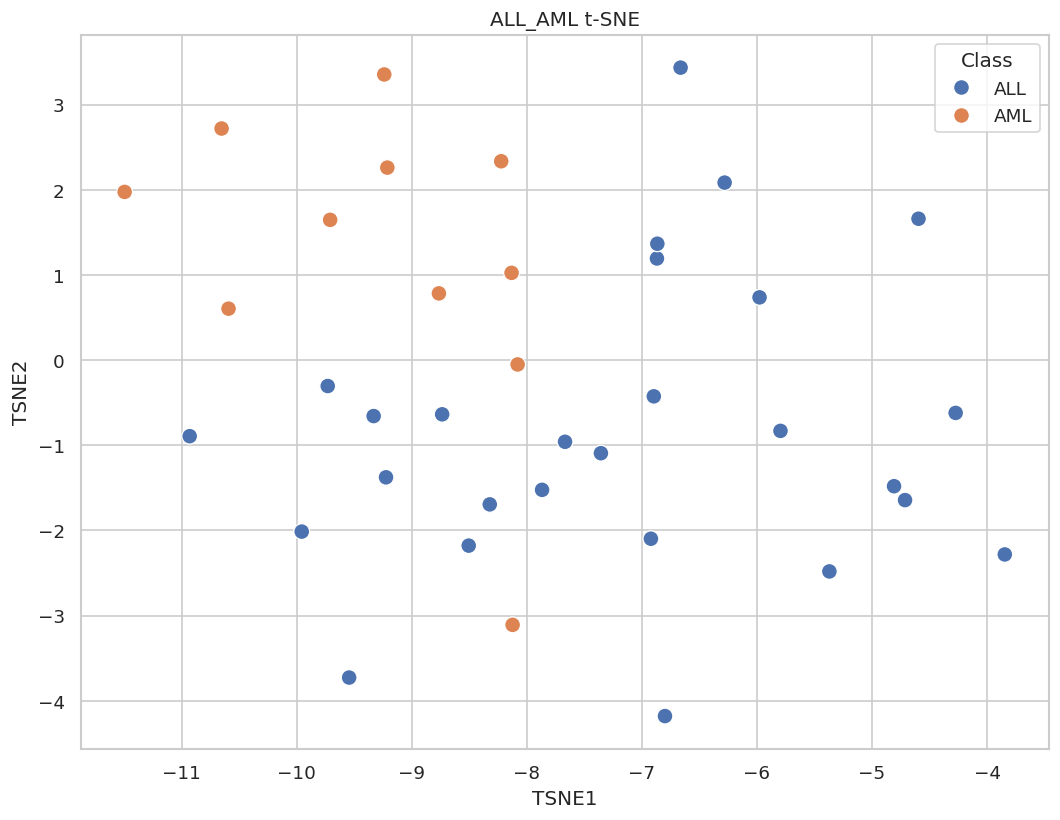

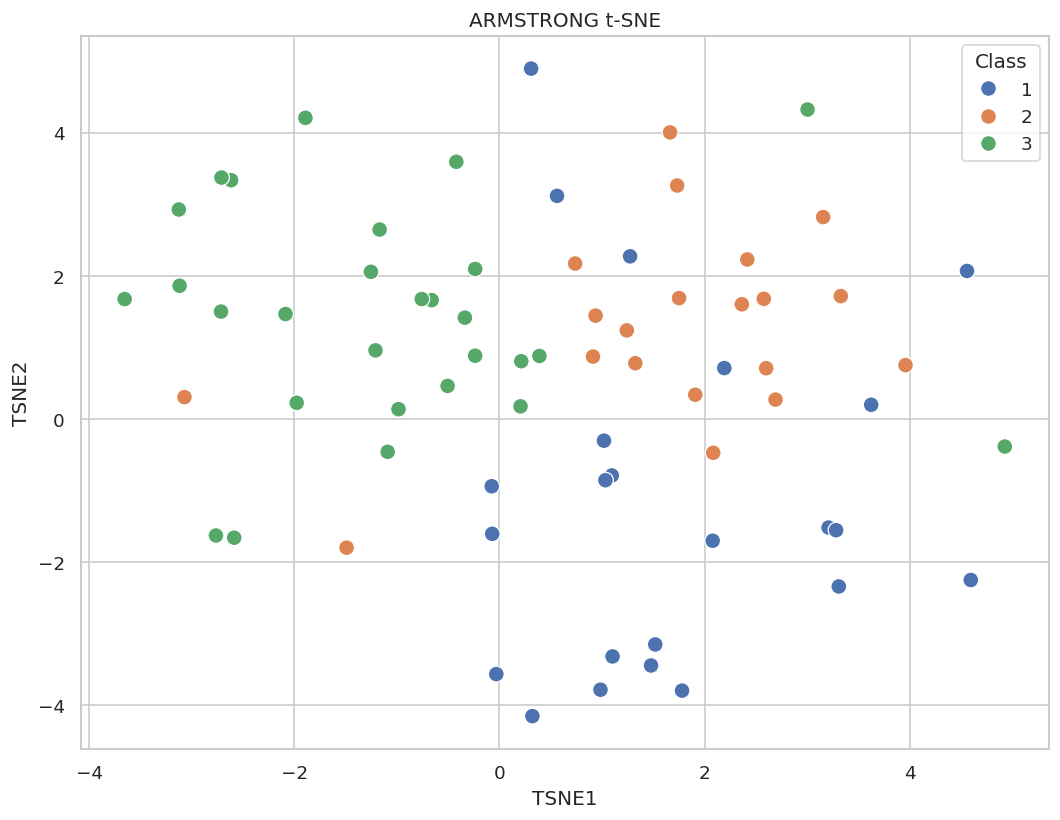

In [12]:
def run_tsne(X, y, dataset_name):

    values, imputer = prepare_for_analysis(X)

    scaled = StandardScaler().fit_transform(values)

    # Önce PCA ile boyut azalt
    n_components = min(
        30,
        scaled.shape[0] - 1,
        scaled.shape[1]
    )

    reduced = PCA(
        n_components=n_components,
        random_state=RANDOM_STATE
    ).fit_transform(scaled)

    perplexity = min(
        20,
        max(2, (len(X)-1)//3)
    )

    tsne = TSNE(
        n_components=2,
        perplexity=perplexity,
        random_state=RANDOM_STATE,
        init="pca",
        learning_rate="auto"
    )

    result = tsne.fit_transform(reduced)

    tsne_df = pd.DataFrame({
        "TSNE1": result[:, 0],
        "TSNE2": result[:, 1],
        "Class": np.asarray(y).astype(str)
    })

    plt.figure(figsize=(9, 7))

    sns.scatterplot(
        data=tsne_df,
        x="TSNE1",
        y="TSNE2",
        hue="Class",
        s=90
    )

    plt.title(f"{dataset_name} t-SNE")

    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/{dataset_name}_TSNE.png",
        dpi=300
    )

    plt.show()

    return tsne_df


all_tsne = run_tsne(
    X_all,
    y_all,
    "ALL_AML"
)

arm_tsne = run_tsne(
    X_arm2,
    y_arm2,
    "ARMSTRONG"
)

In [13]:
def differential_gene_analysis(X, y, dataset_name):

    X = X.copy()

    y = pd.Series(
        np.asarray(y),
        index=X.index
    )

    classes = sorted(y.dropna().unique())

    results = []

    for gene in X.columns:

        groups = [
            X.loc[y == cls, gene].dropna().values
            for cls in classes
        ]

        if any(len(g) < 2 for g in groups):
            continue

        if len(classes) == 2:

            statistic, p_value = mannwhitneyu(
                groups[0],
                groups[1],
                alternative="two-sided"
            )

            test_name = "Mann-Whitney U"

        else:

            statistic, p_value = kruskal(*groups)

            test_name = "Kruskal-Wallis"

        row = {
            "Gene": gene,
            "Test": test_name,
            "Statistic": statistic,
            "P_Value": p_value
        }

        for cls, group_values in zip(classes, groups):

            row[f"Mean_{cls}"] = np.mean(group_values)

            row[f"Median_{cls}"] = np.median(group_values)

        results.append(row)

    result_df = pd.DataFrame(results)

    result_df["FDR"] = multipletests(
        result_df["P_Value"],
        method="fdr_bh"
    )[1]

    result_df = result_df.sort_values(
        "FDR"
    )

    result_df.to_csv(
        f"{OUTPUT_DIR}/{dataset_name}_differential_genes.csv",
        index=False
    )

    significant = result_df[
        result_df["FDR"] < 0.05
    ]

    print(dataset_name)

    print("Toplam test edilen gen:", len(result_df))

    print(
        "FDR < 0.05 gen sayısı:",
        len(significant)
    )

    display(result_df.head(30))

    return result_df


diff_all = differential_gene_analysis(
    X_all,
    y_all,
    "ALL_AML"
)

diff_arm2 = differential_gene_analysis(
    X_arm2,
    y_arm2,
    "ARMSTRONG"
)

ALL_AML
Toplam test edilen gen: 7129
FDR < 0.05 gen sayısı: 441


,Gene,Test,Statistic,P_Value,Mean_ALL,Median_ALL,Mean_AML,Median_AML,FDR
2848,M55150_at,Mann-Whitney U,7.0,0.000006,810.296296,803.0,1836.272727,1753.0,0.003674
901,D88422_at,Mann-Whitney U,6.0,0.000005,145.296296,126.0,2520.363636,1013.0,0.003674
6859,Y12670_at,Mann-Whitney U,7.0,0.000006,411.148148,337.0,1294.454545,1085.0,0.003674
6612,X95735_at,Mann-Whitney U,0.0,0.000002,396.185185,360.0,3023.636364,2947.0,0.003674
2537,M23197_at,Mann-Whitney U,6.0,0.000005,175.037037,152.0,767.272727,774.0,0.003674
2623,M27783_s_at,Mann-Whitney U,5.0,0.000004,89.888889,28.0,2150.090909,1084.0,0.003674
3208,M84526_at,Mann-Whitney U,30.0,0.000002,13.185185,1.0,3513.454545,4573.0,0.003674
2627,M27891_at,Mann-Whitney U,2.0,0.000002,225.703704,36.0,7423.545455,6962.0,0.003674
2388,M16038_at,Mann-Whitney U,7.0,0.000006,375.370370,325.0,1811.636364,1674.0,0.003674
6164,X70297_at,Mann-Whitney U,7.0,0.000006,219.518519,203.0,721.363636,607.0,0.003674


ARMSTRONG
Toplam test edilen gen: 2194
FDR < 0.05 gen sayısı: 197


,Gene,Test,Statistic,P_Value,Mean_1,Median_1,Mean_2,Median_2,Mean_3,Median_3,FDR
1585,38017_at,Kruskal-Wallis,46.993077,6.245726e-11,0.784858,0.849203,0.726612,0.743336,0.994382,1.000000,1.370312e-07
1161,37539_at,Kruskal-Wallis,39.683282,2.414821e-09,1.426395,1.467963,0.968722,1.000000,1.000000,1.000000,2.649058e-06
1016,35164_at,Kruskal-Wallis,38.650390,4.047385e-09,1.471543,1.435504,0.986594,1.000000,1.000000,1.000000,2.751453e-06
681,39318_at,Kruskal-Wallis,38.221137,5.016323e-09,0.893462,0.890189,0.846677,0.890189,0.977161,1.000000,2.751453e-06
1571,37680_at,Kruskal-Wallis,37.232337,8.224333e-09,1.402011,1.406720,0.968746,1.000000,1.012893,1.000000,3.608837e-06
278,36392_at,Kruskal-Wallis,34.857167,2.696884e-08,1.476478,1.515904,0.939204,1.000000,0.988822,1.000000,9.861607e-06
196,34168_at,Kruskal-Wallis,32.115265,1.062329e-07,1.083666,1.110457,0.790849,1.000000,0.976491,1.000000,3.329642e-05
1337,40763_at,Kruskal-Wallis,31.555538,1.405406e-07,1.000000,1.000000,1.290078,1.251955,0.807888,1.000000,3.854327e-05
1678,39878_at,Kruskal-Wallis,27.424928,1.108543e-06,1.191725,1.170561,0.748623,0.847659,0.976342,1.000000,2.702381e-04
1407,32847_at,Kruskal-Wallis,27.057378,1.332187e-06,1.362000,1.436967,0.920850,1.000000,1.000000,1.000000,2.922817e-04


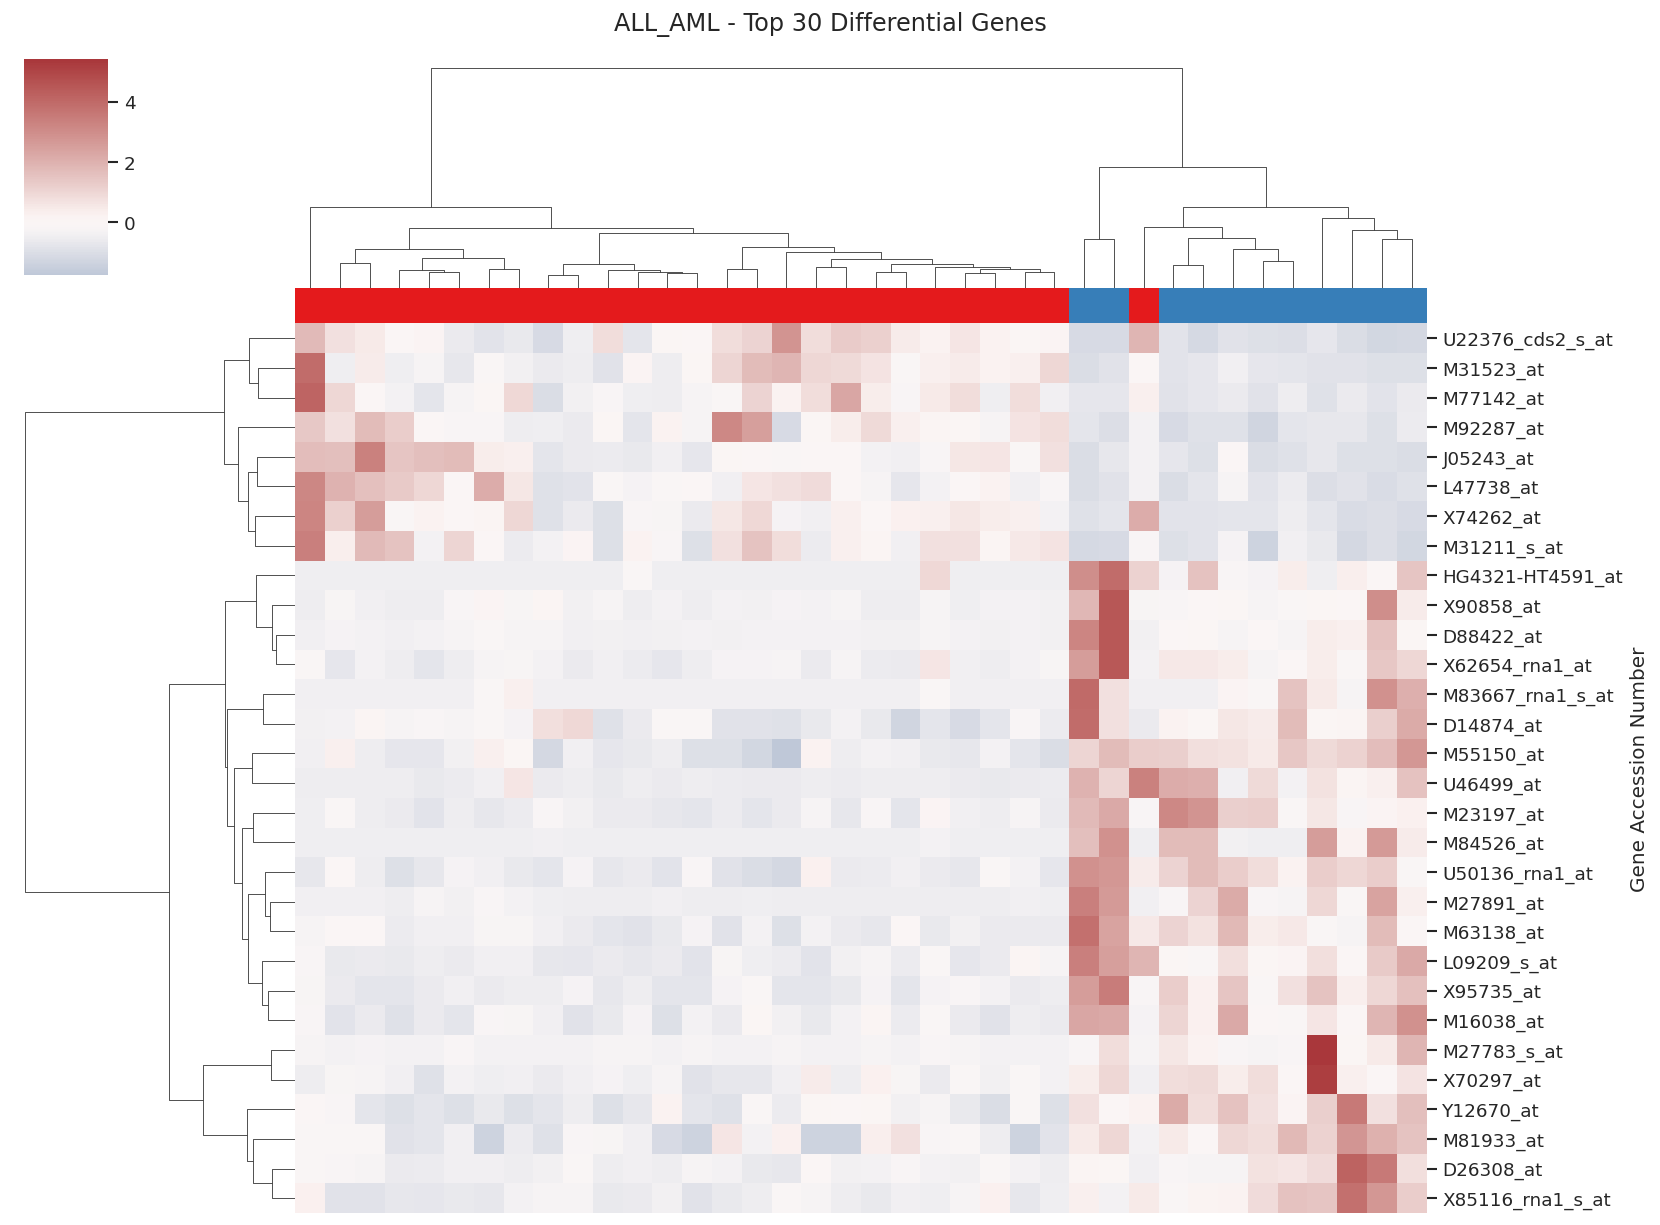

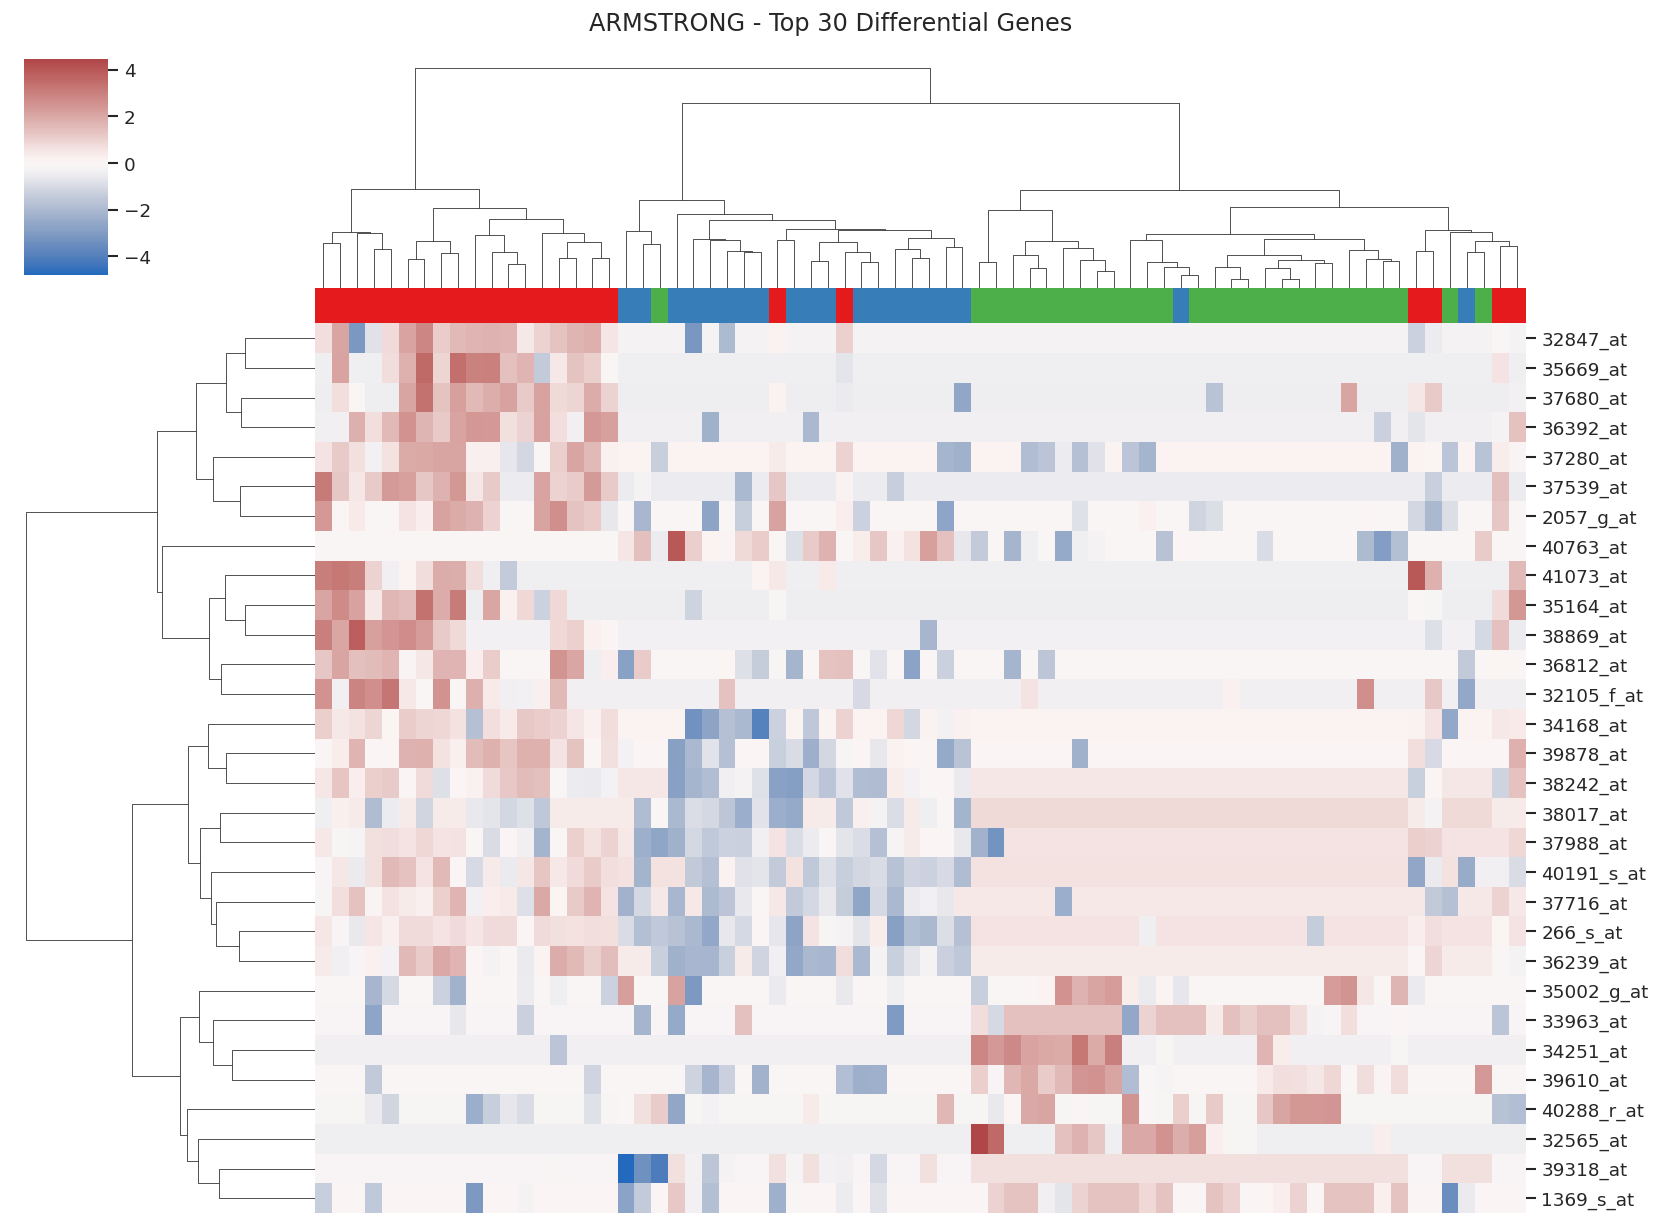

In [14]:
def gene_heatmap(X, y, diff_df, dataset_name):

    top_genes = (
        diff_df.head(TOP_N_GENES)["Gene"].tolist()
    )

    data = X[top_genes].copy()

    # Gen bazında Z-score standardizasyonu
    data = (
        data - data.mean()
    ) / data.std().replace(0, 1)

    data = data.replace(
        [np.inf, -np.inf],
        np.nan
    ).fillna(0)

    # Sınıfları görselleştirme
    labels = np.asarray(y).astype(str)

    palette = sns.color_palette(
        "Set1",
        n_colors=len(np.unique(labels))
    )

    color_map = dict(
        zip(sorted(np.unique(labels)), palette)
    )

    sample_colors = pd.Series(labels).map(
        color_map
    )

    g = sns.clustermap(
        data.T,
        cmap="vlag",
        center=0,
        figsize=(14, 10),
        col_colors=sample_colors.tolist(),
        xticklabels=False,
        yticklabels=True,
        method="ward"
    )

    g.fig.suptitle(
        f"{dataset_name} - Top 30 Differential Genes",
        y=1.02
    )

    g.savefig(
        f"{OUTPUT_DIR}/{dataset_name}_heatmap.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


gene_heatmap(
    X_all,
    y_all,
    diff_all,
    "ALL_AML"
)

gene_heatmap(
    X_arm2,
    y_arm2,
    diff_arm2,
    "ARMSTRONG"
)

Train gen sayısı: 7129
Test gen sayısı: 7129
Ortak gen sayısı: 7129


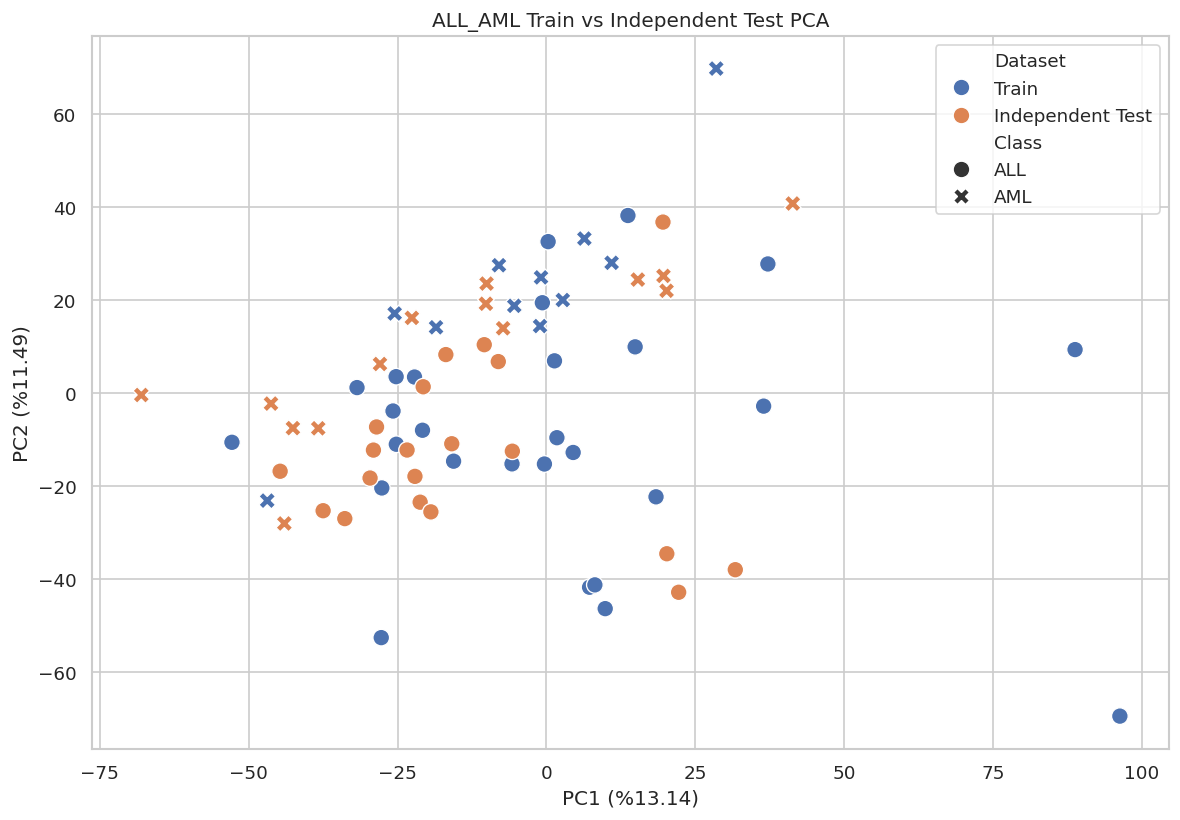

İlk iki bileşenin toplam açıklanan varyansı: 0.2462841744824602


In [15]:
# Ortak genleri belirle
common_genes = X_all.columns.intersection(
    X_independent.columns
)

print("Train gen sayısı:", X_all.shape[1])
print("Test gen sayısı:", X_independent.shape[1])
print("Ortak gen sayısı:", len(common_genes))

if len(common_genes) < 2:
    raise ValueError("Ortak gen sayısı PCA için yetersiz.")

X_train_common = X_all[common_genes].copy()
X_test_common = X_independent[common_genes].copy()

# Sadece eğitim verisine göre imputasyon
imputer = SimpleImputer(strategy="median")

train_imputed = imputer.fit_transform(
    X_train_common
)

test_imputed = imputer.transform(
    X_test_common
)

# Sadece eğitim verisine göre standardizasyon
scaler = StandardScaler()

train_scaled = scaler.fit_transform(
    train_imputed
)

test_scaled = scaler.transform(
    test_imputed
)

# PCA eğitim verisinde öğrenilir
pca = PCA(n_components=2)

train_components = pca.fit_transform(
    train_scaled
)

test_components = pca.transform(
    test_scaled
)

# Sonuçları birleştir
comparison_df = pd.DataFrame({

    "PC1": np.concatenate([
        train_components[:, 0],
        test_components[:, 0]
    ]),

    "PC2": np.concatenate([
        train_components[:, 1],
        test_components[:, 1]
    ]),

    "Dataset": (
        ["Train"] * len(X_train_common) +
        ["Independent Test"] * len(X_test_common)
    ),

    "Class": (
        y_all.astype(str).tolist() +
        y_independent.astype(str).tolist()
    )
})

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=comparison_df,
    x="PC1",
    y="PC2",
    hue="Dataset",
    style="Class",
    s=100
)

plt.title("ALL_AML Train vs Independent Test PCA")

plt.xlabel(
    f"PC1 (%{pca.explained_variance_ratio_[0]*100:.2f})"
)

plt.ylabel(
    f"PC2 (%{pca.explained_variance_ratio_[1]*100:.2f})"
)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/ALL_AML_train_test_PCA.png",
    dpi=300
)

plt.show()

print(
    "İlk iki bileşenin toplam açıklanan varyansı:",
    pca.explained_variance_ratio_.sum()
)

In [16]:
comparison = pd.DataFrame({

    "Train_Mean": X_train_common.mean(),

    "Test_Mean": X_test_common.mean(),

    "Train_Std": X_train_common.std(),

    "Test_Std": X_test_common.std()

})

comparison["Mean_Difference"] = (
    comparison["Train_Mean"] -
    comparison["Test_Mean"]
)

comparison["Std_Difference"] = (
    comparison["Train_Std"] -
    comparison["Test_Std"]
)

comparison.to_csv(
    f"{OUTPUT_DIR}/ALL_AML_train_test_comparison.csv"
)

display(
    comparison.sort_values(
        "Mean_Difference",
        key=abs,
        ascending=False
    ).head(20)
)

,Train_Mean,Test_Mean,Train_Std,Test_Std,Mean_Difference,Std_Difference
Gene Accession Number,,,,,,
hum_alu_at,20276.657895,30722.000000,7546.053808,11473.175442,-10445.342105,-3927.121634
M25079_s_at,14030.210526,21173.441176,12685.760423,18311.265670,-7143.230650,-5625.505246
L06499_at,23828.105263,30713.294118,5527.743515,8174.487209,-6885.188854,-2646.743694
J04617_s_at,17387.605263,24268.176471,4544.039229,7306.869377,-6880.571207,-2762.830148
M26602_at,230.394737,6840.382353,776.254052,13819.320540,-6609.987616,-13043.066488
Z12962_at,17648.315789,23841.735294,3616.522416,6832.663704,-6193.419505,-3216.141288
M26311_s_at,1961.342105,6544.382353,4255.297317,8740.271603,-4583.040248,-4484.974286
X80822_at,16467.078947,21040.470588,3055.945701,5001.147264,-4573.391641,-1945.201563
D49824_s_at,23647.815789,28107.029412,9494.384166,9336.108661,-4459.213622,158.275505


In [17]:
X_arm_train, X_arm_test, y_arm_train, y_arm_test = train_test_split(

    X_arm2,

    y_arm2,

    test_size=0.25,

    random_state=RANDOM_STATE,

    stratify=y_arm2
)

print("Armstrong Train:", X_arm_train.shape)
print("Armstrong Test:", X_arm_test.shape)

print("\nTrain sınıf dağılımı:")
print(y_arm_train.value_counts())

print("\nTest sınıf dağılımı:")
print(y_arm_test.value_counts())

Armstrong Train: (54, 2194)
Armstrong Test: (18, 2194)

Train sınıf dağılımı:
group
3    21
1    18
2    15
Name: count, dtype: int64

Test sınıf dağılımı:
group
3    7
1    6
2    5
Name: count, dtype: int64


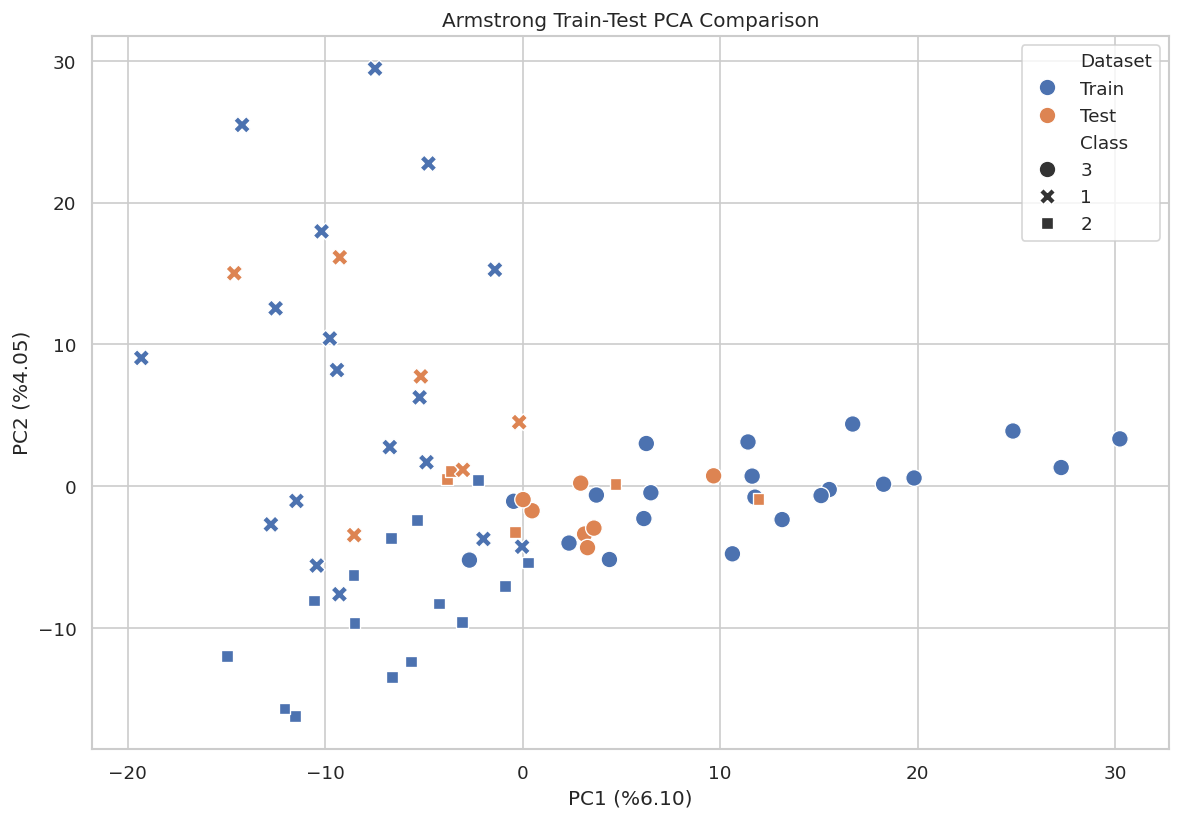

In [18]:
# Imputer yalnızca eğitim verisine fit edilir
imputer_arm = SimpleImputer(
    strategy="median"
)

arm_train_imp = imputer_arm.fit_transform(
    X_arm_train
)

arm_test_imp = imputer_arm.transform(
    X_arm_test
)

# StandardScaler yalnızca eğitim verisine fit edilir
scaler_arm = StandardScaler()

arm_train_scaled = scaler_arm.fit_transform(
    arm_train_imp
)

arm_test_scaled = scaler_arm.transform(
    arm_test_imp
)

# PCA yalnızca eğitim verisinde öğrenilir
pca_arm = PCA(n_components=2)

arm_train_pca = pca_arm.fit_transform(
    arm_train_scaled
)

arm_test_pca = pca_arm.transform(
    arm_test_scaled
)

arm_comparison = pd.DataFrame({

    "PC1": np.concatenate([
        arm_train_pca[:, 0],
        arm_test_pca[:, 0]
    ]),

    "PC2": np.concatenate([
        arm_train_pca[:, 1],
        arm_test_pca[:, 1]
    ]),

    "Dataset": (
        ["Train"] * len(X_arm_train) +
        ["Test"] * len(X_arm_test)
    ),

    "Class": (
        y_arm_train.astype(str).tolist() +
        y_arm_test.astype(str).tolist()
    )
})

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=arm_comparison,
    x="PC1",
    y="PC2",
    hue="Dataset",
    style="Class",
    s=100
)

plt.title("Armstrong Train-Test PCA Comparison")

plt.xlabel(
    f"PC1 (%{pca_arm.explained_variance_ratio_[0]*100:.2f})"
)

plt.ylabel(
    f"PC2 (%{pca_arm.explained_variance_ratio_[1]*100:.2f})"
)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/ARMSTRONG_train_test_PCA.png",
    dpi=300
)

plt.show()

In [19]:
common_genes = X_all.columns.intersection(
    X_arm2.columns
)

print("ALL_AML gen sayısı:", X_all.shape[1])

print("Armstrong gen sayısı:", X_arm2.shape[1])

print("Ortak gen kimliği sayısı:", len(common_genes))

if len(common_genes) >= 2:

    print("Ortak genler üzerinden karşılaştırma yapılabilir.")

    all_common = X_all[common_genes]

    arm_common = X_arm2[common_genes]

    comparison = pd.DataFrame({

        "ALL_AML_Mean": all_common.mean(),

        "Armstrong_Mean": arm_common.mean(),

        "ALL_AML_Std": all_common.std(),

        "Armstrong_Std": arm_common.std()

    })

    display(comparison.head(20))

    comparison.to_csv(
        f"{OUTPUT_DIR}/Cross_Dataset_Gene_Comparison.csv"
    )

else:

    print(
        "Ortak gen kimliği bulunamadı. "
        "Doğrudan gen bazlı karşılaştırma yapılamaz."
    )

    print(
        "Biyolojik anotasyon veya gen sembolleri üzerinden "
        "eşleştirme yapılmalıdır."
    )

ALL_AML gen sayısı: 7129
Armstrong gen sayısı: 2194
Ortak gen kimliği sayısı: 7
Ortak genler üzerinden karşılaştırma yapılabilir.


,ALL_AML_Mean,Armstrong_Mean,ALL_AML_Std,Armstrong_Std
AFFX-HUMISGF3A/M97935_5_at,11.052632,0.959621,60.486741,0.422950
AFFX-HUMISGF3A/M97935_MA_at,120.605263,0.795356,388.333692,0.415648
AFFX-HUMRGE/M10098_5_at,4150.368421,1.041700,5677.672417,0.411662
AFFX-HUMRGE/M10098_M_at,2654.552632,1.160163,4087.028417,0.672695
AFFX-HUMTFRR/M11507_M_at,126.052632,0.940502,231.693641,0.424156
AFFX-M27830_5_at,2579.210526,0.803465,2590.655778,0.527349
AFFX-PheX-3_at,20.026316,1.003410,31.937851,0.252809


In [20]:
# Betimsel istatistikler
stats_all.to_csv(
    f"{OUTPUT_DIR}/ALL_AML_statistics.csv"
)

stats_arm2.to_csv(
    f"{OUTPUT_DIR}/ARMSTRONG_statistics.csv"
)

# PCA varyans sonuçları
pca_results = pd.DataFrame({

    "Dataset": ["ALL_AML", "ARMSTRONG"],

    "PC1": [
        all_pca_model.explained_variance_ratio_[0],
        arm_pca_model.explained_variance_ratio_[0]
    ],

    "PC2": [
        all_pca_model.explained_variance_ratio_[1],
        arm_pca_model.explained_variance_ratio_[1]
    ]

})

pca_results["Total"] = (
    pca_results["PC1"] +
    pca_results["PC2"]
)

pca_results.to_csv(
    f"{OUTPUT_DIR}/PCA_results.csv",
    index=False
)

display(pca_results)

print("\nBütün analizler tamamlandı.")

print("\nOluşturulan dosyalar:")

for file in sorted(os.listdir(OUTPUT_DIR)):
    print(file)

,Dataset,PC1,PC2,Total
0,ALL_AML,0.131374,0.114910,0.246284
1,ARMSTRONG,0.053209,0.035955,0.089164



Bütün analizler tamamlandı.

Oluşturulan dosyalar:
ALL_AML_INDEPENDENT_PAM.csv
ALL_AML_INDEPENDENT_PAM.png
ALL_AML_INDEPENDENT_class_distribution.png
ALL_AML_INDEPENDENT_missing.png
ALL_AML_INDEPENDENT_negative_value_replacement.csv
ALL_AML_INDEPENDENT_outlier_counts.csv
ALL_AML_INDEPENDENT_outliers.png
ALL_AML_INDEPENDENT_quality.csv
ALL_AML_INDEPENDENT_statistics.csv
ALL_AML_PCA.png
ALL_AML_PCA_variance.png
ALL_AML_TRAIN_PAM.csv
ALL_AML_TRAIN_PAM.png
ALL_AML_TRAIN_class_distribution.png
ALL_AML_TRAIN_missing.png
ALL_AML_TRAIN_negative_value_replacement.csv
ALL_AML_TRAIN_outlier_counts.csv
ALL_AML_TRAIN_outliers.png
ALL_AML_TRAIN_quality.csv
ALL_AML_TRAIN_statistics.csv
ALL_AML_TSNE.png
ALL_AML_boxplot.png
ALL_AML_differential_genes.csv
ALL_AML_heatmap.png
ALL_AML_sample_outliers.csv
ALL_AML_sample_outliers.png
ALL_AML_scaler_comparison.png
ALL_AML_statistics.csv
ALL_AML_train_test_PCA.png
ALL_AML_train_test_comparison.csv
ARMSTRONG_PCA.png
ARMSTRONG_PCA_variance.png
ARMSTRONG_TSNE.p